# Prioritising Healthcare Affordability Outreach
### Recall-focused random forest classification and priority-population profiles · DBA3803 Group 12

<a id="overview"></a>
## Overview

<a id="overview-business-problem"></a>
### Identified Business Problem
Healthcare providers have limited staff and resources for financial-assistance and care-navigation outreach. Low income and a lack of insurance may be useful warning signs, but other circumstances can also relate to difficulties accessing care. For context, a [2023 KFF consumer survey](https://www.kff.org/affordable-care-act/kff-survey-of-consumer-experiences-with-health-insurance/) reported that 58% of insured adults experienced at least one problem using their coverage. This broader measure of insurance problems is distinct from the cost-related unmet-care outcome examined here.

This project tests whether combining age, financial circumstances, health and access-to-care characteristics improves the identification of adults who report needing medical care but not receiving it because of cost. The intended business use is to prioritise an assessment of current affordability-related support needs. A prediction does not establish financial-assistance eligibility or a person's future need for care.

<a id="overview-project-focus"></a>
### Project Focus
Given limited outreach capacity, how can a U.S. healthcare provider better prioritise assessments of affordability-related support needs, and what distinct profiles exist among those prioritised?

The project has two objectives:

1. Compare case finding at the same contact capacity against random selection and insurance-only targeting.
2. Describe the priority population using demographic, socioeconomic, healthcare-access and health characteristics to inform possible follow-up questions and support pathways.


## Contents

- [Overview](#overview)
  - [Identified Business Problem](#overview-business-problem)
  - [Project Focus](#overview-project-focus)
- [Part 0: Loading Packages and Requirements](#part-0)
- [Part 1: Data Inspection](#part-1)
  - [Data source, observations and variables](#data-source-observations-variables)
- [Part 2: Clean Data](#part-2)
- [Part 3: Train / Validation / Test Split](#part-3)
- [Part 4: Data Visualisation](#part-4)
- [Part 5: Hypotheses and Transformations](#part-5)
  - [Feature selection](#feature-selection)
  - [Model development hypotheses](#model-development-hypotheses)
- [Part 6: Modelling Priorities and Model Selection](#part-6)
  - [6.1 Random Forest Representations](#part-6-1)
  - [6.2 Random Forest Model and Cutoff Selection](#part-6-2)
  - [6.3 Full-Feature Logistic Regression Benchmark](#part-6-3)
    - [6.3.1 Benchmark Preprocessing and Display Functions](#part-6-3-1)
    - [6.3.2 Cross-Validation, Validation Comparison and Benchmark Refit](#part-6-3-2)
- [Part 7: Model Diagnostics and Business Plausibility](#part-7)
  - [7.1 Random Forest Ranking, Calibration and Predictor Importance](#part-7-1)
  - [7.2 Subgroup Performance and Error Trade-offs](#part-7-2)
  - [7.3 Priority-Population Profiling](#part-7-3)
  - [7.4 Final Random Forest Refit and Procedure Freeze](#part-7-4)
- [Part 8: Final Out-of-Time Evaluation on 2025 Data](#part-8)
  - [8.1 Random Forest Performance and Outreach Trade-offs](#part-8-1)
  - [8.2 Applying the Development Profiles to 2025](#part-8-2)
  - [8.3 Random Forest versus Full-Feature Logistic Regression](#part-8-3)
- [Part 9: Answering the Business Question](#part-9)
  - [9.1 Main findings](#part-9-1)
  - [9.2 Business recommendation](#part-9-2)
  - [9.3 Limitations](#part-9-3)
- [Appendix](#appendix)
  - [A. Key terms and reproducibility](#appendix-a)
  - [B. References](#appendix-b)


<a id="part-0"></a>
## Part 0: Loading Packages and Requirements

In [34]:
from pathlib import Path
import sys, json, time, hashlib, platform
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
import sklearn
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, roc_curve, confusion_matrix,
                             make_scorer, silhouette_score, adjusted_rand_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from kmodes.kprototypes import KPrototypes

RANDOM_STATE = 1
N_JOBS = 4
DATA_DIR = Path('.')
TRAIN_PATH = DATA_DIR / 'nhis_2023_2024.csv'
TEST_PATH = DATA_DIR / 'nhis_2025.csv'
CAPACITIES = (0.05, 0.10, 0.20, 0.30, 0.40, 0.50)
SELECTION_CAPACITIES = (0.05, 0.10, 0.20)
PROFILE_FRACTION = 0.20
TEST_OPENED = False
FIT_LOG = []

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print(f'Python {platform.python_version()} | scikit-learn {sklearn.__version__}')
print('Only the development CSV will be opened initially.')

Python 3.14.7 | scikit-learn 1.9.1
Only the development CSV will be opened initially.


<a id="part-1"></a>
## Part 1: Data Inspection
<a id="data-source-observations-variables"></a>
### Data source, observations and variables
The supplied files are extracts of the **IPUMS National Health Interview Survey (NHIS)**. At this stage, the development extract is inspected in its raw form, with one row representing a survey record. The variables below are grouped by their intended analytical role. Identifiers distinguish records, rather than explain affordability.

| Role | Variables | Reason |
|---|---|---|
| Target | `YBARCARE` | The reported cost-related unmet medical need we want to identify |
| Predictors | `REGION`, `AGE`, `SEX`, `HISPRACE`, `EDUC`, `EMPSTAT`, `POVERTY`, `HEALTH`, `USUALPL`, `HINOTCOVE` | Information potentially available in an intake or patient record |
| Year | `YEAR` | Determines the time split; excluded from model inputs |
| Identifiers | `SERIAL`, `NHISHID`, `PERNUM`, `NHISPID`, `HHX` | Record checks only; excluded from modelling and clustering |
| Survey design | `SAMPWEIGHT`, `STRATA`, `PSU` | Population-oriented summaries and study design, not individual-need predictors |
| Sample flags | `ASTATFLG`, `CSTATFLG` | Select the appropriate sample; excluded as predictors |

Additional notes:
- `POVERTY` is a category of family income relative to the poverty threshold, not an exact income. 
- `HINOTCOVE = 1` means covered and `= 2` means no coverage. 
- `EMPSTAT = 200` means not employed; this includes people outside the labour force, not only people looking for work. 
- `AGE = 85` is top-coded: it should be read as 85 or older. 

Variable definitions follow the IPUMS NHIS documentation.


In [2]:
PREDICTORS = ['REGION', 'AGE', 'SEX', 'HISPRACE', 'EDUC',
              'EMPSTAT', 'POVERTY', 'HEALTH', 'USUALPL', 'HINOTCOVE']
CATEGORICAL = [c for c in PREDICTORS if c != 'AGE']
ID_COLUMNS = ['SERIAL', 'NHISHID', 'PERNUM', 'NHISPID', 'HHX']
DESIGN_COLUMNS = ['SAMPWEIGHT', 'STRATA', 'PSU']
EXCLUDED = ['YBARCARE', 'target', 'YEAR', 'ASTATFLG', 'CSTATFLG'] + ID_COLUMNS + DESIGN_COLUMNS
REQUIRED = set(PREDICTORS + ['YEAR', 'ASTATFLG', 'YBARCARE', 'SAMPWEIGHT', 'NHISPID'])

def verify_structure(data, expected_years, name):
    missing = REQUIRED.difference(data.columns)
    if missing:
        raise ValueError(f'{name} missing columns: {sorted(missing)}')
    years = set(data['YEAR'].dropna().astype(int))
    if years != set(expected_years):
        raise ValueError(f'{name}: years {years}, expected {expected_years}')

if not TRAIN_PATH.exists():
    raise FileNotFoundError('Place the notebook beside nhis_2023_2024.csv.')
development_raw = pd.read_csv(TRAIN_PATH, dtype={'NHISPID': str})
verify_structure(development_raw, {2023, 2024}, 'Development file')
print('Development file shape:', development_raw.shape)
display(development_raw[['YEAR'] + PREDICTORS + ['YBARCARE']].head())
display(pd.DataFrame({'dtype': development_raw.dtypes.astype(str),
                      'raw_missing': development_raw.isna().sum()}))
display(development_raw[['AGE', 'SAMPWEIGHT']].describe().T)
print('Repeated raw person identifiers:', development_raw['NHISPID'].duplicated().sum())

Development file shape: (78203, 22)


,YEAR,REGION,AGE,SEX,HISPRACE,EDUC,EMPSTAT,POVERTY,HEALTH,USUALPL,HINOTCOVE,YBARCARE
0,2023,4,39,1,2,301,100,35,2,1,1,1
1,2023,4,15,2,2,0,0,35,1,2,1,1
2,2023,3,71,2,2,202,200,12,5,2,1,1
3,2023,1,36,1,2,201,100,34,4,2,1,1
4,2023,4,57,2,2,201,100,34,3,2,1,1


,dtype,raw_missing
YEAR,int64,0
SERIAL,int64,0
STRATA,int64,0
PSU,int64,0
NHISHID,str,0
REGION,int64,0
PERNUM,int64,0
NHISPID,str,0
HHX,str,0
SAMPWEIGHT,int64,0


,count,mean,std,min,25%,50%,75%,max
AGE,"78,203.0000",45.5979,44.2325,0.0000,24.0000,45.0000,65.0000,999.0000
SAMPWEIGHT,"78,203.0000","8,467.7091","5,679.5261",265.0000,"4,362.0000","7,086.0000","10,858.0000","39,925.0000"


Repeated raw person identifiers: 0


<a id="part-2"></a>
## Part 2: Clean Data
The following rules are fixed from the IPUMS variable definitions rather than estimated from evaluation data:

1. Keep sample adults (`ASTATFLG == 1`) with valid Yes/No target answers. An unknown outcome cannot provide the correct class, so it is excluded.
2. Convert Yes to target 1 and No to target 0. No other variable changes this label.
3. Replace documented non-response codes with missing values. For example, an unknown age coded 999 is not a 999-year-old adult.
4. Keep records with a positive survey weight to maintain the sample definition and support weighted descriptive analysis.
5. Retain missing predictors. The pipeline learns numeric replacements from its training rows and represents missing categorical responses with a separate label.
6. Do not remove people merely because they share the same survey answers. Check record identifiers separately to distinguish repeated records from different respondents with similar characteristics.


In [3]:
INVALID_CODES = {
    'REGION': [8, 9], 'AGE': [997, 998, 999], 'SEX': [7, 8, 9],
    'HISPRACE': [97, 98, 99], 'EDUC': [0, 996, 997, 998, 999],
    'EMPSTAT': [0, 900, 997, 998, 999], 'POVERTY': [0, 98, 99],
    'HEALTH': [7, 8, 9], 'USUALPL': [0, 7, 8, 9], 'HINOTCOVE': [0, 7, 8, 9]
}

def prepare_nhis(raw):
    data = raw.loc[raw['ASTATFLG'].eq(1) & raw['YBARCARE'].isin([1, 2])].copy()
    data['target'] = data['YBARCARE'].map({1: 0, 2: 1}).astype('int8')
    for column, codes in INVALID_CODES.items():
        data[column] = pd.to_numeric(data[column], errors='coerce')
        data[column] = data[column].mask(data[column].isin(codes))
    data['SAMPWEIGHT'] = pd.to_numeric(data['SAMPWEIGHT'], errors='coerce')
    return data.loc[data['SAMPWEIGHT'].gt(0)].reset_index(drop=True)

def cleaning_summary(raw, cleaned):
    adult = raw['ASTATFLG'].eq(1)
    return pd.DataFrame({'stage': ['Raw records', 'Sample adults', 'Valid adult target',
                                   'Retained after positive-weight check'],
                         'rows': [len(raw), int(adult.sum()),
                                  int((adult & raw['YBARCARE'].isin([1, 2])).sum()), len(cleaned)]})

development = prepare_nhis(development_raw)
assert development['target'].isin([0, 1]).all()
assert development['AGE'].dropna().between(18, 85).all()
assert development['NHISPID'].notna().all() and development['NHISPID'].is_unique
assert not set(PREDICTORS).intersection(EXCLUDED)
display(cleaning_summary(development_raw, development))
missing_table = pd.DataFrame({'missing_n': development[PREDICTORS].isna().sum(),
                              'missing_%': development[PREDICTORS].isna().mean() * 100})
display(missing_table.sort_values('missing_%', ascending=False))
display(development[PREDICTORS].nunique().rename('distinct_observed_values').to_frame())

,stage,rows
0,Raw records,78203
1,Sample adults,62151
2,Valid adult target,61630
3,Retained after positive-weight check,61630


,missing_n,missing_%
EMPSTAT,1982,3.2160
EDUC,281,0.4559
HINOTCOVE,161,0.2612
AGE,109,0.1769
USUALPL,46,0.0746
HEALTH,34,0.0552
SEX,11,0.0178
REGION,0,0.0000
HISPRACE,0,0.0000
POVERTY,0,0.0000


,distinct_observed_values
REGION,4
AGE,68
SEX,2
HISPRACE,7
EDUC,10
EMPSTAT,2
POVERTY,14
HEALTH,5
USUALPL,3
HINOTCOVE,2


<a id="part-3"></a>
## Part 3: Train / Validation / Test Split

This section defines the 2023 training and 2024 validation samples. The table records the planned role of each year in the study design; refitting and evaluation are not performed here. Only the development data are loaded at this stage.

| Sample | Role | Usage |
|---|---|---|
| 2023 | Initial training and five-fold cross-validation | Learn preprocessing and tune model settings using training folds only |
| 2024 | Later-year validation | Compare tuned models and forest finalists; diagnose weaknesses; define descriptive profiles |
| 2023–2024 | Final refit | Relearn the selected model and baseline parameters using both development years |
| 2025 | Out-of-time evaluation | Apply the frozen procedure and report results without further fitting or tuning |

For cross-validation, the 2023 records are divided into five stratified folds with approximately the same proportion of positive cases. Stratification keeps the class balance comparable across folds; it does not remove the imbalance. The pipeline relearns missing-value replacements and category encoding within each training fold.


In [4]:
initial_train = development.loc[development['YEAR'].eq(2023)].reset_index(drop=True)
validation = development.loc[development['YEAR'].eq(2024)].reset_index(drop=True)
X_train, y_train = initial_train[PREDICTORS], initial_train['target']
X_validation, y_validation = validation[PREDICTORS], validation['target']
assert set(initial_train['YEAR']) == {2023} and set(validation['YEAR']) == {2024}
assert set(initial_train['NHISPID']).isdisjoint(validation['NHISPID'])

def fit_development(estimator, X, y, records, name):
    assert not TEST_OPENED, 'Fitting is locked after the evaluation file is opened.'
    assert set(records['YEAR']).issubset({2023, 2024})
    assert len(X) == len(y) == len(records)
    assert list(X.columns) == PREDICTORS
    FIT_LOG.append({'step': name, 'years': sorted(records['YEAR'].unique().tolist()), 'rows': len(X)})
    return estimator.fit(X, y)

display(development.groupby('YEAR').agg(adults=('target', 'size'),
                                       cases=('target', 'sum'), prevalence=('target', 'mean')))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for train_idx, held_idx in cv.split(X_train, y_train):
    assert set(train_idx).isdisjoint(held_idx)
print('Five 2023-only folds are defined. No 2025 data have been loaded.')

,adults,cases,prevalence
YEAR,,,
2023,29276,1716,0.0586
2024,32354,2195,0.0678


Five 2023-only folds are defined. No 2025 data have been loaded.


<a id="part-4"></a>
## Part 4: Data Visualisation
The charts use 2023–2024 development data. Group rates use survey weights, while respondent counts are unweighted. These descriptive patterns motivate modelling choices; they do not establish causal relationships.


,year,adults,cases,sample_rate,weighted_rate
0,2023,29276,1716,0.0586,0.0633
1,2024,32354,2195,0.0678,0.0739


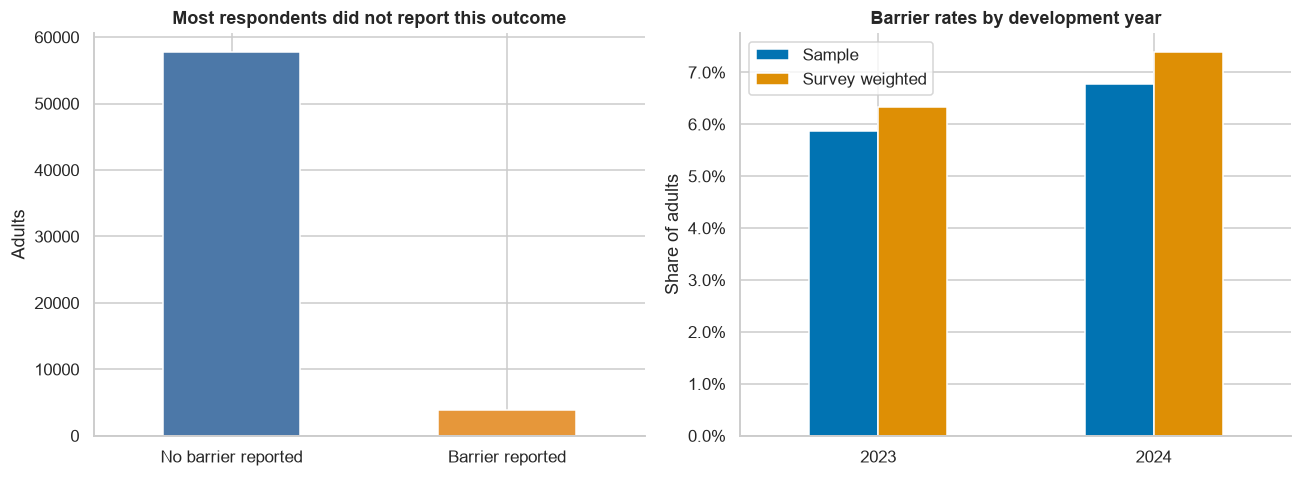

In [5]:
LABELS = {
 'REGION': {1: 'Northeast', 2: 'Midwest', 3: 'South', 4: 'West'},
 'SEX': {1: 'Male', 2: 'Female'},
 'HISPRACE': {1: 'Hispanic', 2: 'Non-Hispanic White', 3: 'Non-Hispanic Black',
              4: 'Non-Hispanic Asian', 5: 'Non-Hispanic AI/AN',
              6: 'Non-Hispanic AI/AN + other', 7: 'Non-Hispanic other/multiple'},
 'EMPSTAT': {100: 'Employed', 200: 'Not employed'},
 'HEALTH': {1: 'Excellent', 2: 'Very good', 3: 'Good', 4: 'Fair', 5: 'Poor'},
 'USUALPL': {1: 'No usual place', 2: 'Has usual place', 3: 'More than one place'},
 'HINOTCOVE': {1: 'Covered', 2: 'Not covered'},
 'POVERTY': {11: '<0.50', 12: '0.50–0.74', 13: '0.75–0.99', 21: '1.00–1.24',
             22: '1.25–1.49', 23: '1.50–1.74', 24: '1.75–1.99', 31: '2.00–2.49',
             32: '2.50–2.99', 33: '3.00–3.49', 34: '3.50–3.99', 35: '4.00–4.49',
             36: '4.50–4.99', 37: '5.00+'},
 'EDUC': {103: 'Grades 1–11', 116: 'Grade 12, no diploma', 201: 'High-school diploma',
          202: 'GED', 301: 'Some college', 302: 'Associate, vocational',
          303: 'Associate, academic', 400: "Bachelor's", 510: "Master's",
          520: 'Professional / doctorate'}
}

def category_label(value, column):
    if pd.isna(value):
        return 'Missing'
    return LABELS.get(column, {}).get(int(value), f'Code {int(value)}')

def weighted_binary_rate(data):
    return float(np.average(data['target'], weights=data['SAMPWEIGHT']))

def weighted_rate_by(data, column):
    # Retain missing answers as a visible group rather than silently deleting them.
    d = data[[column, 'target', 'SAMPWEIGHT']].copy()
    d['weighted_positive'] = d['target'] * d['SAMPWEIGHT']
    table = d.groupby(column, dropna=False, observed=True).agg(
        n=('target', 'size'), positive_cases=('target', 'sum'),
        unweighted_rate=('target', 'mean'), total_weight=('SAMPWEIGHT', 'sum'),
        weighted_positive=('weighted_positive', 'sum')).reset_index()
    table['weighted_rate'] = table['weighted_positive'] / table['total_weight']
    table['label'] = table[column].map(lambda x: category_label(x, column))
    return table

prevalence = pd.DataFrame([{'year': str(year), 'adults': len(g), 'cases': int(g['target'].sum()),
                           'sample_rate': g['target'].mean(),
                           'weighted_rate': weighted_binary_rate(g)}
                          for year, g in development.groupby('YEAR')])
display(prevalence)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
development['target'].value_counts().sort_index().plot.bar(
    ax=axes[0], color=['#4C78A8', '#E6973A'], rot=0)
axes[0].set(xticklabels=['No barrier reported', 'Barrier reported'], ylabel='Adults',
            xlabel='', title='Most respondents did not report this outcome')
prevalence.set_index('year')[['sample_rate', 'weighted_rate']].plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Barrier rates by development year', ylabel='Share of adults', xlabel='')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(['Sample', 'Survey weighted'])
plt.tight_layout(); plt.show()

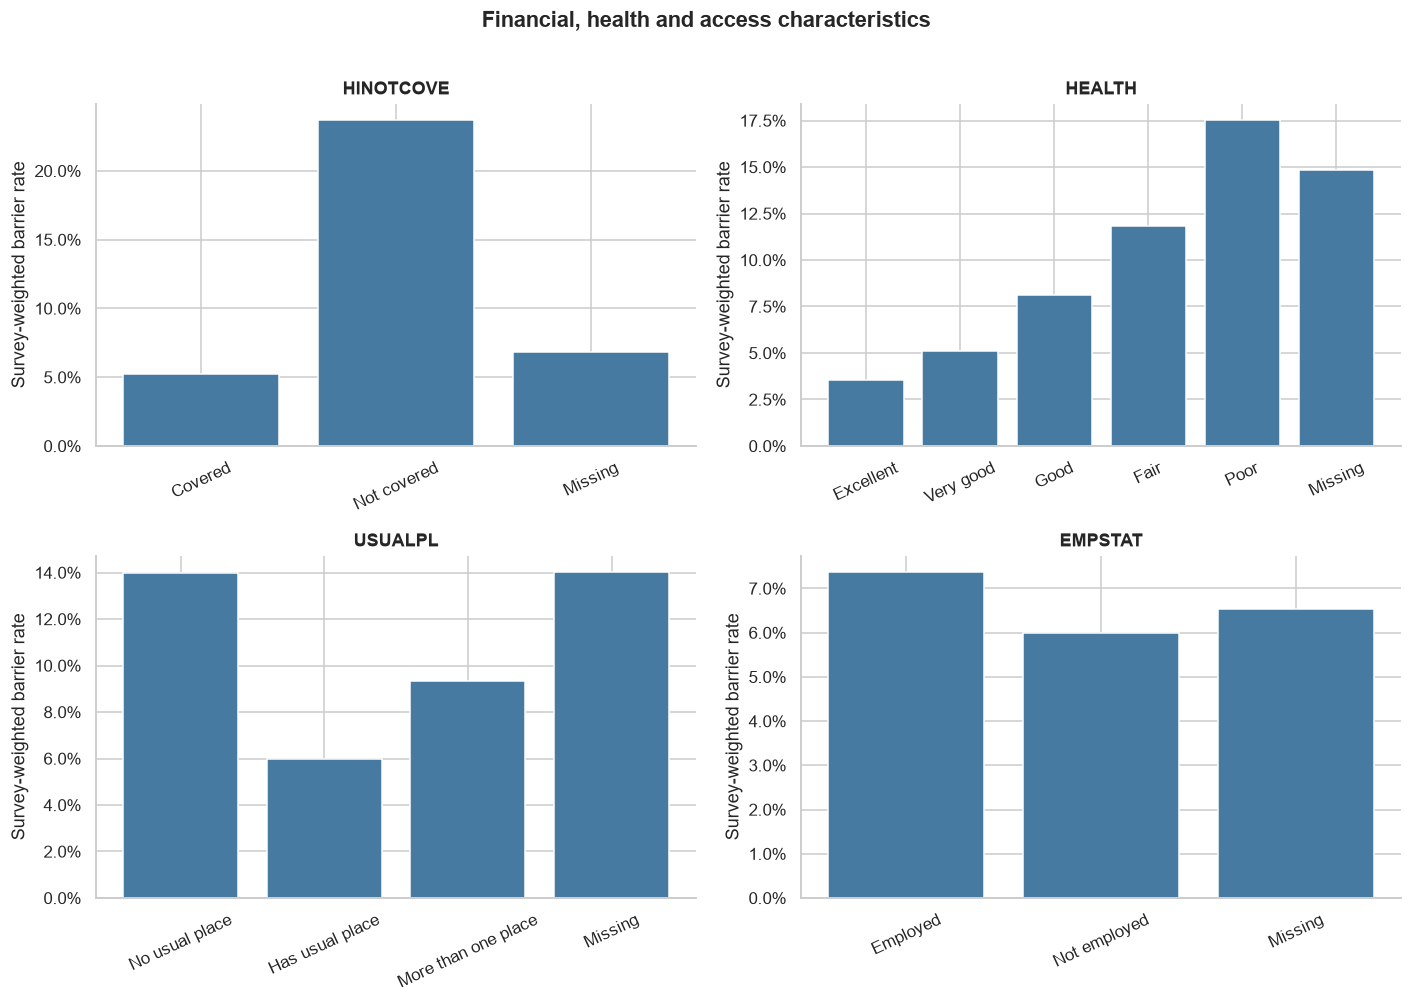

,label,n,positive_cases,weighted_rate
0,Covered,57166,2878,0.0523
1,Not covered,4303,1023,0.2371
2,Missing,161,10,0.0680


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, column in zip(axes.flat, ['HINOTCOVE', 'HEALTH', 'USUALPL', 'EMPSTAT']):
    rates = weighted_rate_by(development, column)
    ax.bar(rates['label'], rates['weighted_rate'], color='#467AA0')
    ax.set(title=column, ylabel='Survey-weighted barrier rate')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(axis='x', rotation=25)
plt.suptitle('Financial, health and access characteristics', y=1.01, weight='bold')
plt.tight_layout(); plt.show()
insurance_rates = weighted_rate_by(development, 'HINOTCOVE')
display(insurance_rates[['label', 'n', 'positive_cases', 'weighted_rate']])
covered_rate = insurance_rates.loc[insurance_rates['HINOTCOVE'].eq(1), 'weighted_rate'].iloc[0]
uncovered_rate = insurance_rates.loc[insurance_rates['HINOTCOVE'].eq(2), 'weighted_rate'].iloc[0]

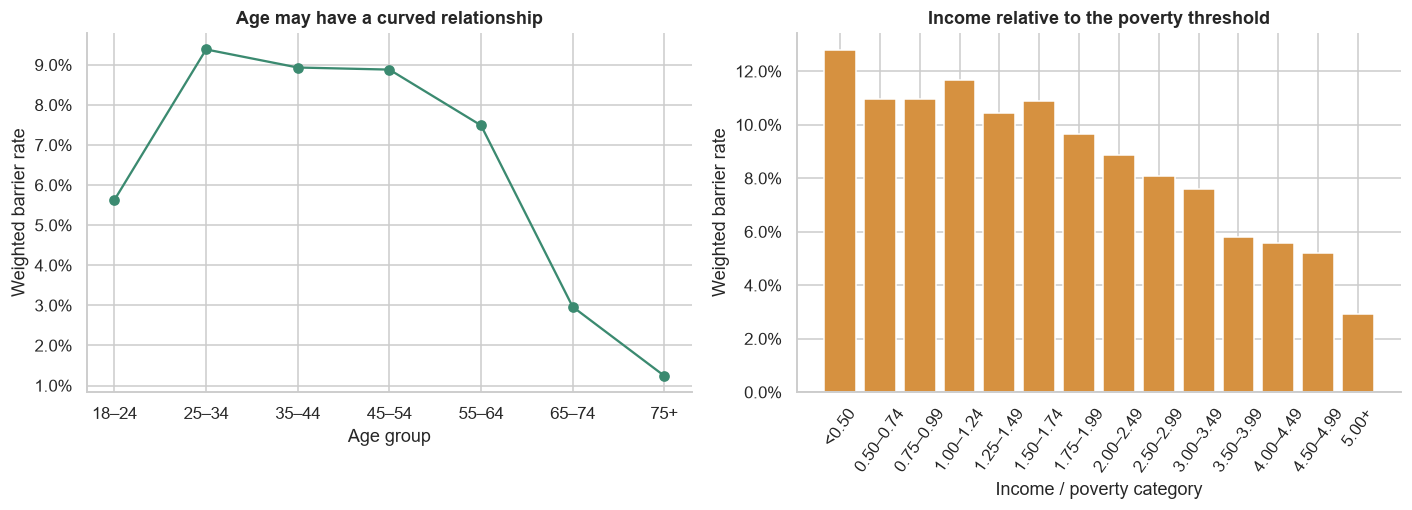

In [7]:
age_data = development.copy()
age_data['AGE_GROUP'] = pd.cut(age_data['AGE'], [17, 24, 34, 44, 54, 64, 74, np.inf],
                               labels=['18–24', '25–34', '35–44', '45–54', '55–64', '65–74', '75+'])
age_rates = age_data.groupby('AGE_GROUP', observed=True).apply(
    lambda g: np.average(g['target'], weights=g['SAMPWEIGHT']), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(age_rates.index.astype(str), age_rates.values, marker='o', color='#3B8A70')
axes[0].set(title='Age may have a curved relationship', xlabel='Age group', ylabel='Weighted barrier rate')
pov_rates = weighted_rate_by(development, 'POVERTY')
axes[1].bar(pov_rates['label'], pov_rates['weighted_rate'], color='#D69140')
axes[1].set(title='Income relative to the poverty threshold', xlabel='Income / poverty category',
            ylabel='Weighted barrier rate')
axes[1].tick_params(axis='x', rotation=55)
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()

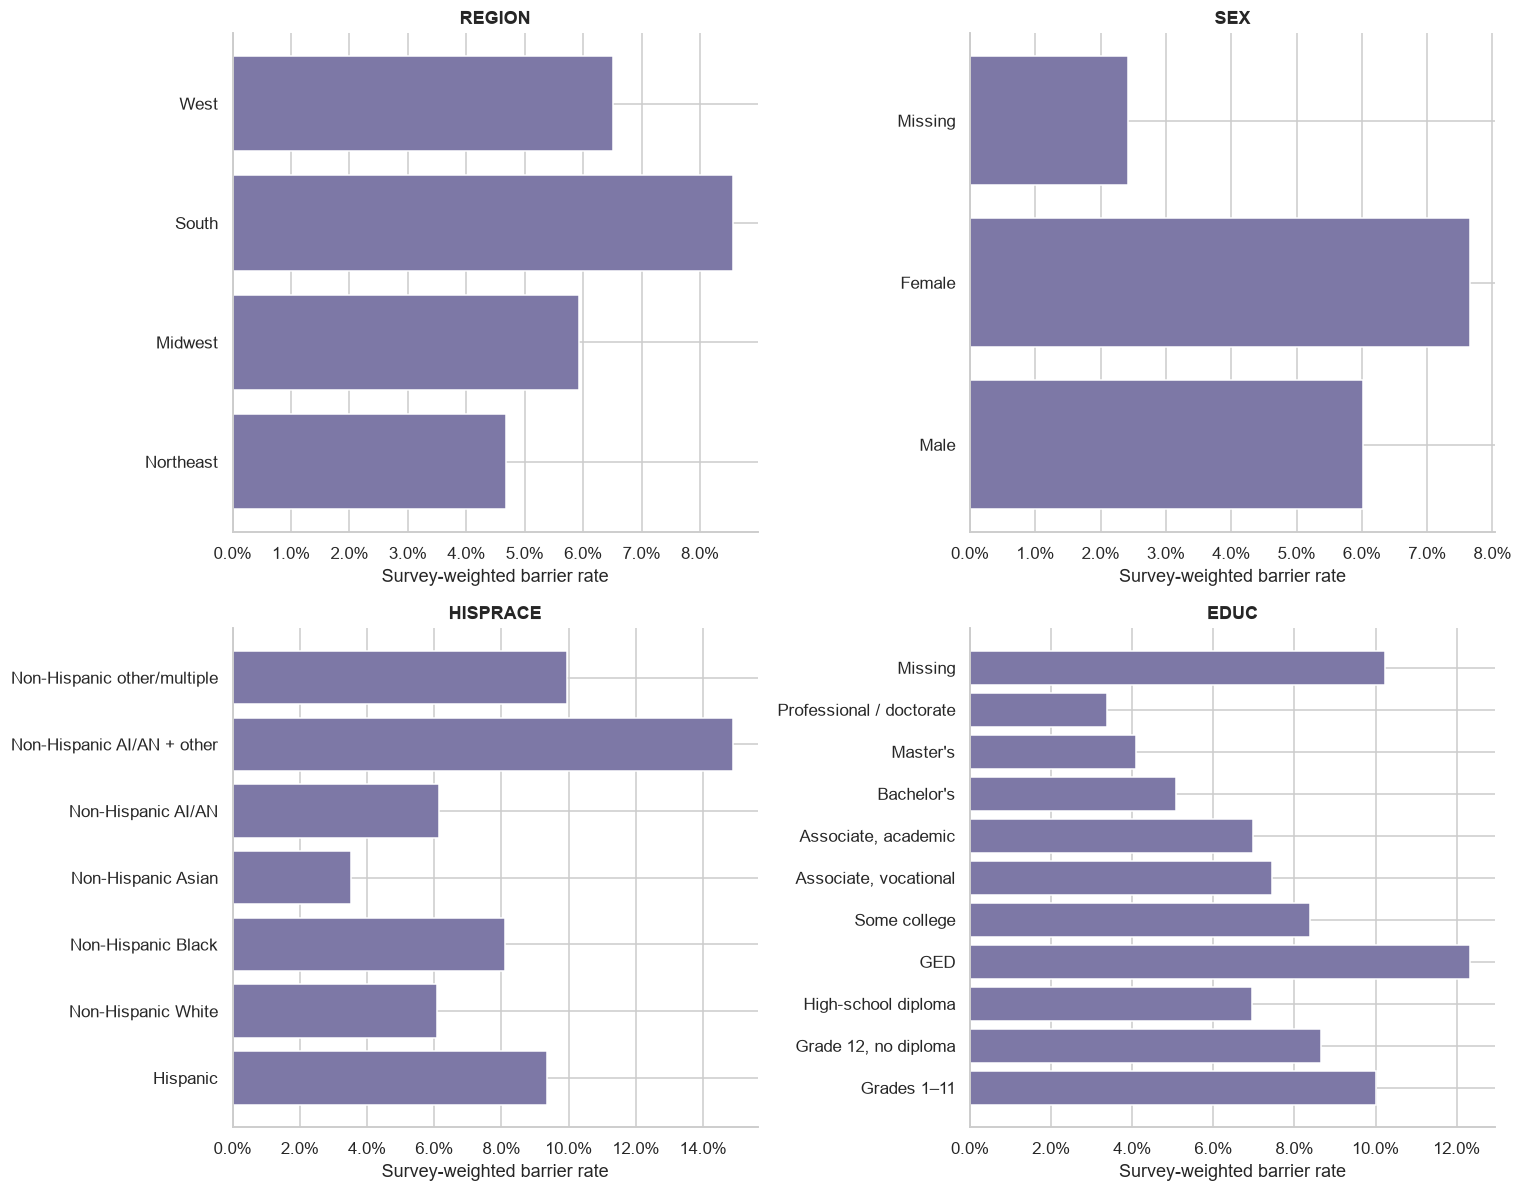

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, column in zip(axes.flat, ['REGION', 'SEX', 'HISPRACE', 'EDUC']):
    rates = weighted_rate_by(development, column)
    ax.barh(rates['label'], rates['weighted_rate'], color='#7D78A6')
    ax.set(title=column, xlabel='Survey-weighted barrier rate')
    ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()

<a id="part-5"></a>
## Part 5: Hypotheses and Transformations
<a id="feature-selection"></a>
### Feature selection

| Feature | Reason for inclusion |
|---|---|
| `HINOTCOVE` | Coverage may reduce financial exposure, but coverage alone cannot describe all affordability problems |
| `POVERTY` | Income relative to family needs gives information about financial resources |
| `HEALTH` | Self-rated health may distinguish adults with different care needs and financial exposure |
| `USUALPL` | A usual place for care may capture differences in access and care navigation |
| `EMPSTAT` | Employment status may relate to financial circumstances and coverage |
| `AGE` | Life stage, health needs and coverage arrangements may vary across adulthood |
| `EDUC` | May provide additional socioeconomic information; it does not directly measure financial literacy |
| `REGION` | Regional differences may add information; broad regions do not identify a particular clinic's market |
| `SEX` | May help describe observed differences and assess who the model identifies |
| `HISPRACE` | May capture observed disparities and support subgroup checks; it is not a biological or causal explanation |

**Other variables used:**
- **`YBARCARE`:** The target variable indicating whether the respondent reported being unable to obtain needed medical care because of cost.
- **Person IDs:** Used to check record uniqueness.
- **Survey weights (`SAMPWEIGHT`):** Used for survey-weighted descriptive statistics. Model fitting and predictive-performance metrics are unweighted.
- **Sampling-design fields (`STRATA`, `PSU`):** Describe the survey’s sampling structure and were excluded from model inputs.
- **Sample-adult flag (`ASTATFLG`):** Used to select respondents included in the sample-adult interview.
- **`YEAR`:** Used to separate training, validation and evaluation samples and excluded from the predictors.

Other unmet-care and delayed-care measures were not included as predictors because they could closely overlap with the target outcome and introduce data leakage.

<a id="model-development-hypotheses"></a>
### Model development hypotheses

The following predictive hypotheses guide model development:

1. **Including multiple characteristics may improve target prediction.**
Combining financial circumstances, health, demographics and healthcare access may identify reported affordability barriers more effectively than insurance status alone. This supports including several predictors and comparing the forest with insurance-only targeting.

2. **Age has a nonlinear relationship with reported barriers.**
The association may vary across life stages rather than increase or decrease consistently. Random forests can capture these patterns through different age splits.

3. **Predictors may interact.**
For example, the association between health and reported affordability barriers may differ depending on income and insurance coverage. Successive tree branches allow the forest to learn these combinations.

4. **Ordered representations may improve prediction.**
Representing poverty, education and health in their meaningful order may help trees identify patterns across adjacent levels. The hybrid approach additionally retains category indicators to capture differences specific to individual categories.


In [9]:
def make_preprocessor(age_mode='raw', columns=None):
    cats = CATEGORICAL if columns is None else [c for c in columns if c != 'AGE']
    parts = []
    if columns is None or 'AGE' in columns:
        age_steps = [('impute', SimpleImputer(strategy='median'))]
        if age_mode == 'quadratic':
            age_steps += [('square', PolynomialFeatures(degree=2, include_bias=False)),
                          ('scale', StandardScaler())]
        elif age_mode == 'spline':
            age_steps += [('spline', SplineTransformer(n_knots=5, degree=3, include_bias=False)),
                          ('scale', StandardScaler())]
        elif age_mode == 'scaled':
            age_steps += [('scale', StandardScaler())]
        parts.append(('age', Pipeline(age_steps), ['AGE']))
    if cats:
        categorical_steps = Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value=-1)),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ])
        parts.append(('category', categorical_steps, cats))
    return ColumnTransformer(parts, remainder='drop')

def model_pipeline(model, age_mode='raw', columns=None):
    return Pipeline([('prepare', make_preprocessor(age_mode, columns)), ('model', model)])

def rank_indices(scores):
    scores = np.asarray(scores, dtype=float)
    if not np.isfinite(scores).all():
        raise ValueError('All scores must be finite.')
    # Fixed random tie order is independent of targets and person IDs.
    ties = np.random.default_rng(RANDOM_STATE).permutation(len(scores))
    return np.lexsort((ties, -scores))

def select_top_k(scores, k):
    k = int(k)
    if not 0 <= k <= len(scores):
        raise ValueError('K must be between 0 and the number scored.')
    selected = np.zeros(len(scores), dtype=bool)
    selected[rank_indices(scores)[:k]] = True
    return selected

def capacity_metrics(y_true, scores, fraction):
    y = np.asarray(y_true, dtype=int)
    k = int(np.ceil(fraction * len(y)))
    selected = select_top_k(scores, k)
    tp = int(y[selected].sum())
    fp = k - tp
    fn = int(y.sum()) - tp
    tn = len(y) - tp - fp - fn
    precision = tp / k if k else 0.0
    recall = tp / y.sum() if y.sum() else 0.0
    return {'capacity': fraction, 'contacts': k, 'cases_found': tp, 'false_positives': fp,
            'missed_cases': fn, 'true_negatives': tn, 'precision': precision,
            'recall': recall, 'lift': precision / y.mean() if y.mean() else np.nan}

def mean_capacity_recall(y_true, scores):
    return float(np.mean([capacity_metrics(y_true, scores, q)['recall']
                          for q in SELECTION_CAPACITIES]))

capacity_scorer = make_scorer(mean_capacity_recall, response_method='predict_proba')
scoring = {'mean_capacity_recall': capacity_scorer, 'AP': 'average_precision', 'ROC_AUC': 'roc_auc'}

def overall_metrics(y, scores):
    return {'AP': average_precision_score(y, scores), 'ROC_AUC': roc_auc_score(y, scores),
            'Brier': brier_score_loss(y, scores)}

def table_at_capacities(y, score_dictionary, capacities=CAPACITIES):
    return pd.DataFrame([{'method': name, **capacity_metrics(y, scores, q)}
                         for name, scores in score_dictionary.items() for q in capacities])

<a id="part-6"></a>
## Part 6: Modelling Priorities and Model Selection

<a id="part-6-1"></a>
### 6.1 Random Forest Representations
| Representation | What changes | Business rationale |
|---|---|---|
| One-hot reference | Separate indicators for each survey category | Preserves the original approach without assuming nominal codes have a numeric meaning |
| Ordered | Income-to-poverty, education and health are represented in ranked order; other categories remain one-hot | Lets a tree group adjacent levels, instead of needing several separate splits to describe broader financial or health patterns |
| Hybrid | Retains both ordered values and category indicators for these three inputs | Tests whether broad gradients and particular categories provide complementary information |

<a id="part-6-2"></a>
### 6.2 Random Forest Model and Cutoff Selection
1. **2023 five-fold CV** compares forest settings using average precision (AP). This first screens ranking quality without choosing an operating cutoff from the CV assessment folds.
2. The best **two settings per representation**, plus the original forest reference, are evaluated on **2024**. Each receives a cutoff chosen to maximise **F2** on 2024. F2 gives recall greater emphasis than precision; it is an explicit analytical preference for this revision, not an estimated financial cost ratio.
3. The model-and-cutoff combination with the highest validation F2 is selected. Exact ties favour higher recall, then fewer false positives, then an assigned priority: original reference, One-hot, Ordered and Hybrid. This priority is not a measured model-complexity score. The selected model and cutoff are fixed after this validation comparison.
4. A **conservative alternative cutoff** is also frozen. On 2024 it finds as many cases as possible while allowing no more false positives than the original forest's illustrative 10% list. This is an experimental comparison anchor, not an established provider budget.

Compare the original and selected forests at the same contact capacities on 2024. This distinguishes ranking performance from the effect of making a longer list. These validation scores are used for model selection and can be optimistic.


In [10]:
ORDER_MAPS = {
    'POVERTY': {11: 1, 12: 2, 13: 3, 21: 4, 22: 5, 23: 6, 24: 7,
                31: 8, 32: 9, 33: 10, 34: 11, 35: 12, 36: 13, 37: 14},
    'EDUC': {103: 0, 116: 1, 201: 2, 202: 2, 301: 3, 302: 4, 303: 4,
             400: 5, 510: 6, 520: 7},
    'HEALTH': {1: 1, 2: 2, 3: 3, 4: 4, 5: 5}
}
ORDERED = ['POVERTY', 'EDUC', 'HEALTH']
for col in ORDERED:
    # Check development codes against the documented map; no evaluation read.
    assert set(development[col].dropna()).issubset(ORDER_MAPS[col])

def revised_pipeline(representation, parameters):
    if representation == 'One-hot':
        return model_pipeline(RandomForestClassifier(n_estimators=150, n_jobs=1,
            random_state=RANDOM_STATE, **parameters))
    numeric = ['AGE'] + ORDERED
    categorical = CATEGORICAL if representation == 'Hybrid' else [c for c in CATEGORICAL if c not in ORDERED]
    mapping = FunctionTransformer(pd.DataFrame.replace,
        kw_args={'to_replace': ORDER_MAPS}, validate=False, feature_names_out='one-to-one')
    preprocess = ColumnTransformer([
        ('ordered_numeric', Pipeline([('rank_codes', mapping),
            ('impute', SimpleImputer(strategy='median', add_indicator=True))]), numeric),
        ('categories', Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value=-1)),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical)
    ])
    # This is a fixed codebook mapping, not an estimate learned from outcomes.
    return Pipeline([('prepare', preprocess),
        ('model', RandomForestClassifier(n_estimators=150, n_jobs=1,
                                         random_state=RANDOM_STATE, **parameters))])

FOREST_SETTINGS = [
    {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'},
    {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 0.7, 'class_weight': None},
    {'max_depth': 12, 'min_samples_leaf': 40, 'max_features': 0.7, 'class_weight': None},
    {'max_depth': None, 'min_samples_leaf': 80, 'max_features': 1.0, 'class_weight': None},
    {'max_depth': None, 'min_samples_leaf': 8, 'max_features': 0.7, 'class_weight': 'balanced_subsample'},
    {'max_depth': 16, 'min_samples_leaf': 20, 'max_features': 1.0, 'class_weight': {0: 1, 1: 3}},
    {'max_depth': None, 'min_samples_leaf': 60, 'max_features': 0.7, 'class_weight': {0: 1, 1: 3}},
    {'max_depth': 8, 'min_samples_leaf': 80, 'max_features': 1.0, 'class_weight': 'balanced_subsample'}
]

def threshold_table(y_true, scores):
    y, p = np.asarray(y_true, dtype=int), np.asarray(scores, dtype=float)
    order = np.argsort(-p, kind='stable')
    ordered_p, ordered_y = p[order], y[order]
    end = np.r_[np.flatnonzero(ordered_p[:-1] != ordered_p[1:]), len(p)-1]
    tp = np.cumsum(ordered_y)[end]
    contacts = end + 1
    fp, fn = contacts - tp, y.sum() - tp
    precision = np.divide(tp, contacts, out=np.zeros(len(tp), dtype=float), where=contacts > 0)
    recall = tp / y.sum()
    f2 = np.divide(5*tp, 5*tp + 4*fn + fp, out=np.zeros(len(tp), dtype=float),
                   where=(5*tp + 4*fn + fp) > 0)
    return pd.DataFrame({'cutoff': ordered_p[end], 'cases_found': tp, 'false_positives': fp,
        'missed_cases': fn, 'contacts': contacts, 'precision': precision, 'recall': recall, 'F2': f2})

def choose_f2(y, scores):
    return threshold_table(y, scores).sort_values(
        ['F2', 'recall', 'false_positives', 'cutoff'], ascending=[False, False, True, False]).iloc[0]

def binary_metrics(y_true, selected):
    y, selected = np.asarray(y_true, dtype=int), np.asarray(selected, dtype=bool)
    tp = int(y[selected].sum()); fp = int(selected.sum())-tp
    fn = int(y.sum())-tp; tn = int((1-y).sum())-fp
    return {'cases_found': tp, 'missed_cases': fn, 'false_positives': fp,
            'true_negatives': tn, 'flagged': int(selected.sum()),
            'precision': tp/(tp+fp) if tp+fp else 0,
            'recall': tp/(tp+fn) if tp+fn else 0,
            'F2': 5*tp/(5*tp + 4*fn + fp) if 5*tp+4*fn+fp else 0}

In [11]:
assert not TEST_OPENED
original_validation_model = revised_pipeline('One-hot', FOREST_SETTINGS[0])
fit_development(original_validation_model, X_train, y_train, initial_train, 'Original forest reference: 2023')
original_validation_scores = original_validation_model.predict_proba(X_validation)[:, 1]
original_f2_choice = choose_f2(y_validation, original_validation_scores)
original_fixed_cutoff = float(original_f2_choice['cutoff'])

representation_searches, candidate_models, candidate_scores, rows = {}, {}, {}, []
candidate_models['Original forest reference'] = original_validation_model
candidate_scores['Original forest reference'] = original_validation_scores
rows.append({'candidate': 'Original forest reference', 'representation': 'One-hot',
              'complexity': 0, 'settings': FOREST_SETTINGS[0],
              'CV_AP': np.nan, 'validation_AP': average_precision_score(y_validation, original_validation_scores),
              **original_f2_choice.to_dict()})

for representation in ['One-hot', 'Ordered', 'Hybrid']:
    estimator = revised_pipeline(representation, FOREST_SETTINGS[0])
    grid = [{f'model__{key}': [value] for key, value in setting.items()} for setting in FOREST_SETTINGS]
    search = GridSearchCV(estimator, grid, scoring={'AP': 'average_precision', 'AUC': 'roc_auc'},
                          refit='AP', cv=cv, n_jobs=N_JOBS, error_score='raise')
    started = time.perf_counter()
    fit_development(search, X_train, y_train, initial_train, representation + ': 2023 five-fold search')
    representation_searches[representation] = search
    results = pd.DataFrame(search.cv_results_).sort_values('mean_test_AP', ascending=False)
    for number, (_, result) in enumerate(results.head(2).iterrows(), 1):
        name = f'{representation} finalist {number}'
        model = clone(search.estimator).set_params(**result['params'])
        fit_development(model, X_train, y_train, initial_train, name + ': 2023 fit')
        scores = model.predict_proba(X_validation)[:, 1]
        choice = choose_f2(y_validation, scores)
        candidate_models[name], candidate_scores[name] = model, scores
        rows.append({'candidate': name, 'representation': representation,
                      'complexity': ['One-hot', 'Ordered', 'Hybrid'].index(representation) + 1,
                      'settings': result['params'], 'CV_AP': result['mean_test_AP'],
                      'validation_AP': average_precision_score(y_validation, scores), **choice.to_dict()})
    print(f'Completed {representation}: {time.perf_counter()-started:.1f}s', flush=True)

recall_comparison = pd.DataFrame(rows).sort_values(
    ['F2', 'recall', 'false_positives', 'complexity'], ascending=[False, False, True, True]).reset_index(drop=True)
selected_forest_name = recall_comparison.iloc[0]['candidate']
selected_validation_model = candidate_models[selected_forest_name]
selected_validation_scores = candidate_scores[selected_forest_name]
fixed_recall_cutoff = float(recall_comparison.iloc[0]['cutoff'])

old_val_selection = select_top_k(original_validation_scores, int(np.ceil(0.10 * len(validation))))
original_validation_point = binary_metrics(y_validation, old_val_selection)
conservative_candidates = threshold_table(y_validation, selected_validation_scores)
conservative_candidates = conservative_candidates.loc[
    conservative_candidates['false_positives'] <= original_validation_point['false_positives']]
conservative_choice = conservative_candidates.sort_values(
    ['cases_found', 'false_positives', 'cutoff'], ascending=[False, True, False]).iloc[0]
fixed_conservative_cutoff = float(conservative_choice['cutoff'])
display(recall_comparison[['candidate', 'CV_AP', 'validation_AP', 'cutoff',
    'recall', 'precision', 'F2', 'missed_cases', 'false_positives']])
print('Selected forest:', selected_forest_name)
print('Recall-first cutoff:', repr(fixed_recall_cutoff))
print('Conservative cutoff:', repr(fixed_conservative_cutoff))

Completed One-hot: 67.8s
Completed Ordered: 47.0s
Completed Hybrid: 65.5s


,candidate,CV_AP,validation_AP,cutoff,recall,precision,F2,missed_cases,false_positives
0,Original forest reference,NaN,0.2082,0.4606,0.6410,0.1586,0.3986,788.0000,"7,464.0000"
1,One-hot finalist 1,0.2205,0.2082,0.4606,0.6410,0.1586,0.3986,788.0000,"7,464.0000"
2,Hybrid finalist 1,0.2249,0.2078,0.4510,0.6483,0.1568,0.3985,772.0000,"7,652.0000"
3,Ordered finalist 2,0.2214,0.2043,0.5022,0.5786,0.1751,0.3961,925.0000,"5,982.0000"
4,Hybrid finalist 2,0.2228,0.2087,0.0634,0.6752,0.1483,0.3948,713.0000,"8,508.0000"
5,Ordered finalist 1,0.2222,0.2086,0.0629,0.6797,0.1474,0.3946,703.0000,"8,632.0000"
6,One-hot finalist 2,0.2168,0.2108,0.0778,0.5945,0.1636,0.3894,890.0000,"6,671.0000"


Selected forest: Original forest reference
Recall-first cutoff: 0.4605569290333606
Conservative cutoff: 0.6520894097021713


In [12]:
insurance_validation_model = model_pipeline(LogisticRegression(C=1.0, max_iter=2500), columns=['HINOTCOVE'])
fit_development(insurance_validation_model, X_train, y_train, initial_train, 'Insurance baseline: 2023')
constant_validation_model = DummyClassifier(strategy='prior')
fit_development(constant_validation_model, X_train, y_train, initial_train, 'Constant baseline: 2023')
validation_score_dictionary = {'Random forest': selected_validation_scores,
    'Original forest': original_validation_scores,
    'Insurance only': insurance_validation_model.predict_proba(X_validation)[:, 1]}
validation_capacity_table = table_at_capacities(y_validation, validation_score_dictionary)
validation_operating = pd.DataFrame([
    {'procedure': 'Original forest: illustrative 10% list', **original_validation_point},
    {'procedure': 'Original forest: F2 cutoff', **binary_metrics(y_validation, original_validation_scores >= original_fixed_cutoff)},
    {'procedure': 'Revised forest: F2 cutoff', **binary_metrics(y_validation, selected_validation_scores >= fixed_recall_cutoff)},
    {'procedure': 'Revised forest: conservative cutoff', **binary_metrics(y_validation, selected_validation_scores >= fixed_conservative_cutoff)}])
display(validation_operating)
display(validation_capacity_table[['method', 'capacity', 'contacts', 'cases_found', 'missed_cases',
                                    'false_positives', 'recall', 'precision', 'lift']])

,procedure,cases_found,missed_cases,false_positives,true_negatives,flagged,precision,recall,F2
0,Original forest: illustrative 10% list,774,1421,2462,27697,3236,0.2392,0.3526,0.3221
1,Original forest: F2 cutoff,1407,788,7464,22695,8871,0.1586,0.6410,0.3986
2,Revised forest: F2 cutoff,1407,788,7464,22695,8871,0.1586,0.6410,0.3986
3,Revised forest: conservative cutoff,774,1421,2454,27705,3228,0.2398,0.3526,0.3223


,method,capacity,contacts,cases_found,missed_cases,false_positives,recall,precision,lift
0,Random forest,0.0500,1618,459,1736,1159,0.2091,0.2837,4.1815
1,Random forest,0.1000,3236,774,1421,2462,0.3526,0.2392,3.5255
2,Random forest,0.2000,6471,1174,1021,5297,0.5349,0.1814,2.6742
3,Random forest,0.3000,9707,1466,729,8241,0.6679,0.1510,2.2261
4,Random forest,0.4000,12942,1657,538,11285,0.7549,0.1280,1.8872
5,Random forest,0.5000,16177,1832,363,14345,0.8346,0.1132,1.6692
6,Original forest,0.0500,1618,459,1736,1159,0.2091,0.2837,4.1815
7,Original forest,0.1000,3236,774,1421,2462,0.3526,0.2392,3.5255
8,Original forest,0.2000,6471,1174,1021,5297,0.5349,0.1814,2.6742
9,Original forest,0.3000,9707,1466,729,8241,0.6679,0.1510,2.2261


In [13]:
# Format a display copy so the underlying scores and cutoffs retain full precision.
def show_cutoff_table(table, formats, caption):
    formatted = table.copy().reset_index(drop=True)
    for column, pattern in formats.items():
        if column in formatted:
            formatted[column] = formatted[column].map(pattern.format)
    display(Markdown('**' + caption + '**'))
    display(formatted)

# Recheck the existing choice using only the 2024 validation scores.
assert not TEST_OPENED
assert set(validation['YEAR']) == {2024}
cutoff_search_review = threshold_table(y_validation, selected_validation_scores)
cutoff_search_ranked = cutoff_search_review.sort_values(
    ['F2', 'recall', 'false_positives', 'cutoff'],
    ascending=[False, False, True, False]).reset_index(drop=True)
assert float(cutoff_search_ranked.iloc[0]['cutoff']) == fixed_recall_cutoff

print(f'Validation adults: {len(y_validation):,}; reported cases: {int(y_validation.sum()):,}')
print(f'Distinct score cutoffs compared: {len(cutoff_search_ranked):,}')
print('Selected full-precision cutoff:', repr(fixed_recall_cutoff))

# These illustrative rows explain the trade-off; selection used all cutoffs above.
cutoff_examples = [
    ('Lower cutoff example', 0.30),
    ('Lower cutoff example', 0.40),
    ('SELECTED: highest validation F2', fixed_recall_cutoff),
    ('Common default for comparison', 0.50),
    ('Higher cutoff example', 0.60),
    ('Conservative FP-constrained alternative', fixed_conservative_cutoff),
]
cutoff_review_rows = []
for rule, cutoff in cutoff_examples:
    measures = binary_metrics(y_validation, selected_validation_scores >= cutoff)
    cutoff_review_rows.append({'rule': rule, 'cutoff': cutoff, **measures,
                              'share_flagged': measures['flagged'] / len(y_validation)})
validation_cutoff_review = pd.DataFrame(cutoff_review_rows).sort_values('cutoff')
review_columns = ['rule', 'cutoff', 'cases_found', 'missed_cases', 'false_positives',
                  'flagged', 'share_flagged', 'recall', 'precision', 'F2']
review_formats = {'cutoff': '{:.6f}', 'share_flagged': '{:.1%}',
                  'recall': '{:.1%}', 'precision': '{:.1%}', 'F2': '{:.6f}'}
review_formats.update({c: '{:,.0f}' for c in
                      ['cases_found', 'missed_cases', 'false_positives', 'flagged']})
show_cutoff_table(validation_cutoff_review[review_columns], review_formats,
                  '2024 validation: selected cutoff and alternatives')

top_cutoffs_review = cutoff_search_ranked.head(5).copy()
top_cutoffs_review['rank'] = np.arange(1, len(top_cutoffs_review) + 1)
show_cutoff_table(top_cutoffs_review[['rank', 'cutoff', 'cases_found', 'missed_cases',
        'false_positives', 'contacts', 'recall', 'precision', 'F2']], {
            'cutoff': '{:.9f}', 'recall': '{:.2%}', 'precision': '{:.2%}',
            'F2': '{:.9f}', 'cases_found': '{:,.0f}', 'missed_cases': '{:,.0f}',
            'false_positives': '{:,.0f}', 'contacts': '{:,.0f}'},
        '2024 validation: five highest-F2 cutoffs')

Validation adults: 32,354; reported cases: 2,195
Distinct score cutoffs compared: 29,265
Selected full-precision cutoff: 0.4605569290333606


**2024 validation: selected cutoff and alternatives**

,rule,cutoff,cases_found,missed_cases,false_positives,flagged,share_flagged,recall,precision,F2
0,Lower cutoff example,0.300000,"1,842",353,"14,526","16,368",50.6%,83.9%,11.3%,0.366232
1,Lower cutoff example,0.400000,"1,582",613,"9,952","11,534",35.6%,72.1%,13.7%,0.389387
2,SELECTED: highest validation F2,0.460557,"1,407",788,"7,464","8,871",27.4%,64.1%,15.9%,0.398561
3,Common default for comparison,0.500000,"1,254",941,"6,134","7,388",22.8%,57.1%,17.0%,0.387803
4,Higher cutoff example,0.600000,928,"1,267","3,469","4,397",13.6%,42.3%,21.1%,0.352129
5,Conservative FP-constrained alternative,0.652089,774,"1,421","2,454","3,228",10.0%,35.3%,24.0%,0.322285


**2024 validation: five highest-F2 cutoffs**

,rank,cutoff,cases_found,missed_cases,false_positives,contacts,recall,precision,F2
0,1,0.460556929,"1,407",788,"7,464","8,871",64.10%,15.86%,0.398560988
1,2,0.460524640,"1,407",788,"7,465","8,872",64.10%,15.86%,0.398538409
2,3,0.460497378,"1,407",788,"7,467","8,874",64.10%,15.86%,0.398493259
3,4,0.460792874,"1,406",789,"7,456","8,862",64.05%,15.87%,0.398480898
4,5,0.460486614,"1,407",788,"7,468","8,875",64.10%,15.85%,0.398470688


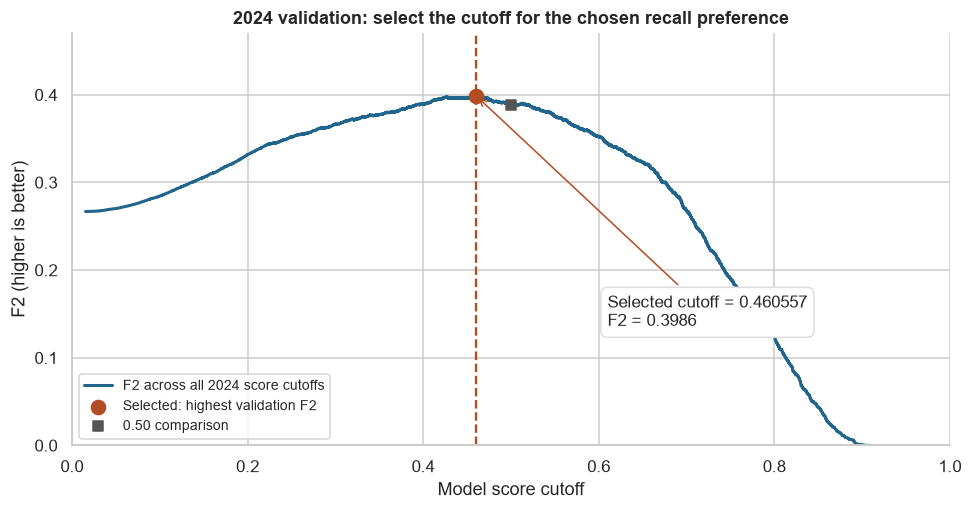

In [14]:
# Show where the chosen cutoff sits on the full validation F2 curve.
curve_review = cutoff_search_review.sort_values('cutoff')
chosen_review = cutoff_search_ranked.iloc[0]
default_review = validation_cutoff_review.loc[
    validation_cutoff_review['rule'].eq('Common default for comparison')].iloc[0]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(curve_review['cutoff'], curve_review['F2'], color='#22658c',
        linewidth=2, label='F2 across all 2024 score cutoffs')
ax.axvline(fixed_recall_cutoff, color='#b34c22', linestyle='--', linewidth=1.5)
ax.scatter([fixed_recall_cutoff], [chosen_review['F2']], color='#b34c22',
           s=85, zorder=4, label='Selected: highest validation F2')
ax.scatter([0.50], [default_review['F2']], color='#555555', marker='s',
           s=48, zorder=4, label='0.50 comparison')
ax.annotate(f"Selected cutoff = {fixed_recall_cutoff:.6f}\nF2 = {chosen_review['F2']:.4f}",
            xy=(fixed_recall_cutoff, chosen_review['F2']),
            xytext=(0.61, 0.29), textcoords='axes fraction',
            arrowprops={'arrowstyle': '->', 'color': '#b34c22'}, fontsize=11,
            bbox={'boxstyle': 'round,pad=0.4', 'facecolor': 'white', 'edgecolor': '#ddd'})
ax.set(xlim=(0, 1), ylim=(0, max(0.46, float(chosen_review['F2']) * 1.18)),
       xlabel='Model score cutoff', ylabel='F2 (higher is better)',
       title='2024 validation: select the cutoff for the chosen recall preference')
ax.legend(loc='lower left', frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

In [15]:
# Translate the measured trade-offs into a business explanation.
selected_review = validation_cutoff_review.loc[
    validation_cutoff_review['rule'].eq('SELECTED: highest validation F2')].iloc[0]
lower_review = validation_cutoff_review.loc[validation_cutoff_review['cutoff'].eq(0.30)].iloc[0]
conservative_review = validation_cutoff_review.loc[
    validation_cutoff_review['rule'].eq('Conservative FP-constrained alternative')].iloc[0]
original_review = binary_metrics(y_validation,
    original_validation_scores >= original_fixed_cutoff)

**Validation selection result.** The retained model is **Original forest reference**, which uses one-hot categorical predictors and numeric age. It and One-hot finalist 1 share the best saved 2024 F2 (**0.3986**), recall (**64.1%**) and false-positive count (**7,464**); the assigned priority retains the original reference. Ordered and Hybrid finalists do not improve validation F2 in this run. The reference is fitted directly on 2023 with predefined settings, so its `CV_AP` is intentionally not recorded (`NaN`). The frozen recall-first cutoff is **0.4605569290333606**; the conservative cutoff is **0.6520894097021713**.

<a id="part-6-3"></a>
### 6.3 Full-Feature Logistic Regression Benchmark

Compare the forest with regularised logistic regression using the same ten predictors and respondents.

Test linear age, curved age, and curved age with insurance interactions. Tune regularisation using five-fold 2023 CV, select the specification and F2 cutoff on 2024, then refit on 2023–2024.

<a id="part-6-3-1"></a>
#### 6.3.1 Benchmark Preprocessing and Display Functions


In [16]:
def rfcomp_features(frame, interactions=False):
    """Create deterministic interaction labels from a copy of the predictors."""
    out = frame.copy()
    if interactions:
        labels = {
            column: out[column].map(
                lambda value: str(int(value)) if pd.notna(value) else "Missing"
            )
            for column in ["HINOTCOVE", "POVERTY", "HEALTH"]
        }
        out["INSURANCE_POVERTY"] = labels["HINOTCOVE"] + "|" + labels["POVERTY"]
        out["INSURANCE_HEALTH"] = labels["HINOTCOVE"] + "|" + labels["HEALTH"]
    return out


def rfcomp_centre_age(values):
    """Express age in decades around a fixed value before polynomial expansion."""
    return (values - 50.0) / 10.0


def rfcomp_logistic_pipeline(quadratic=False, interactions=False):
    """Fit preprocessing within each training fold using the ten original inputs."""
    age_steps = [
        ("impute", SimpleImputer(strategy="median")),
        ("centre", FunctionTransformer(rfcomp_centre_age)),
    ]
    if quadratic:
        age_steps.append(("curve", PolynomialFeatures(degree=2, include_bias=False)))
    age_steps.append(("scale", StandardScaler()))
    parts = [
        ("age", Pipeline(age_steps), ["AGE"]),
        (
            "categories",
            Pipeline(
                [
                    ("impute", SimpleImputer(strategy="constant", fill_value=-1)),
                    (
                        "encode",
                        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                    ),
                ]
            ),
            CATEGORICAL,
        ),
    ]
    if interactions:
        parts.append(
            (
                "interactions",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                ["INSURANCE_POVERTY", "INSURANCE_HEALTH"],
            )
        )
    return Pipeline(
        [
            (
                "features",
                FunctionTransformer(
                    rfcomp_features, kw_args={"interactions": interactions}
                ),
            ),
            ("prepare", ColumnTransformer(parts, remainder="drop")),
            (
                "model",
                LogisticRegression(
                    solver="lbfgs", max_iter=5000, random_state=RANDOM_STATE
                ),
            ),
        ]
    )


def rfcomp_display(table, caption):
    """Format a display copy with colours readable in light and dark themes."""
    frame = table.copy().reset_index(drop=True)
    formats = {}
    for column in frame:
        if column in ["capacity", "precision", "recall", "selected_share"]:
            formats[column] = "{:.1%}"
        elif column == "cutoff":
            formats[column] = "{:.6f}"
        elif pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,.0f}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = "{:.4f}"
    styled = frame.style.format(formats, na_rep="—").set_caption(caption)
    styled = styled.set_table_styles(
        [
            {
                "selector": "",
                "props": [
                    ("color", "#111827 !important"),
                    ("background-color", "#ffffff !important"),
                ],
            },
            {
                "selector": "caption",
                "props": [
                    ("color", "#111827 !important"),
                    ("background-color", "#e2e8f0 !important"),
                    ("text-align", "left"),
                    ("font-weight", "bold"),
                    ("padding", "0.6em"),
                ],
            },
            {
                "selector": "th",
                "props": [
                    ("color", "#ffffff !important"),
                    ("background-color", "#1e293b !important"),
                    ("padding", "0.5em"),
                ],
            },
            {
                "selector": "td",
                "props": [
                    ("color", "#111827 !important"),
                    ("background-color", "#ffffff !important"),
                    ("padding", "0.5em"),
                ],
            },
            {
                "selector": "tbody tr:nth-child(even) td",
                "props": [("background-color", "#f1f5f9 !important")],
            },
        ]
    ).hide(axis="index")
    display({"text/html": styled.to_html(), "text/plain": styled.to_string()}, raw=True)


def rfcomp_original_development_state():
    """Fingerprint the existing inputs and forest state without changing them."""
    import pickle

    objects = (
        PREDICTORS,
        CATEGORICAL,
        RANDOM_STATE,
        CAPACITIES,
        FIT_LOG,
        X_train,
        y_train,
        X_validation,
        y_validation,
        development,
        selected_forest_name,
        selected_validation_model,
        selected_validation_scores,
        fixed_recall_cutoff,
        original_fixed_cutoff,
        fixed_conservative_cutoff,
    )
    return hashlib.sha256(pickle.dumps(objects)).hexdigest()

<a id="part-6-3-2"></a>
#### 6.3.2 Cross-Validation, Validation Comparison and Benchmark Refit

Tables 6.3.1–6.3.4 report candidate selection and validation comparisons.

In [17]:
# All fitting and selection below occur before the evaluation file is opened.
assert not TEST_OPENED, "Restart the kernel and run Part 6.3 before Part 8."
assert set(initial_train["YEAR"]) == {2023}
assert set(validation["YEAR"]) == {2024}
assert set(development["YEAR"]) == {2023, 2024}
assert list(X_train.columns) == list(X_validation.columns) == PREDICTORS
rfcomp_original_state = rfcomp_original_development_state()
rfcomp_cv_splits = list(cv.split(X_train, y_train))
assert len(rfcomp_cv_splits) == 5
# Confirm that the comparator receives the same folds as the forest searches.
for rfcomp_search in representation_searches.values():
    assert all(
        np.array_equal(a, c) and np.array_equal(b, d)
        for (a, b), (c, d) in zip(
            rfcomp_cv_splits, rfcomp_search.cv.split(X_train, y_train)
        )
    )

rfcomp_C_grid = [0.01, 0.1, 1.0, 10.0]
rfcomp_models, rfcomp_validation_scores, rfcomp_rows = {}, {}, []
rfcomp_fit_log = []
for rfcomp_complexity, (rfcomp_name, rfcomp_curve, rfcomp_interactions) in enumerate(
    [
        ("LR: Linear age", False, False),
        ("LR: Curved age", True, False),
        ("LR: Curved age + insurance interactions", True, True),
    ]
):
    assert not TEST_OPENED
    rfcomp_search = GridSearchCV(
        rfcomp_logistic_pipeline(rfcomp_curve, rfcomp_interactions),
        {"model__C": rfcomp_C_grid},
        scoring="average_precision",
        cv=rfcomp_cv_splits,
        refit=True,
        n_jobs=N_JOBS,
        error_score="raise",
    )
    rfcomp_search.fit(X_train, y_train)
    rfcomp_fit_log.append({"step": rfcomp_name, "years": [2023]})
    rfcomp_models[rfcomp_name] = rfcomp_search.best_estimator_
    rfcomp_scores = rfcomp_search.predict_proba(X_validation)[:, 1]
    rfcomp_validation_scores[rfcomp_name] = rfcomp_scores
    rfcomp_choice = choose_f2(y_validation, rfcomp_scores)
    rfcomp_rows.append(
        {
            "candidate": rfcomp_name,
            "complexity": rfcomp_complexity,
            "C": rfcomp_search.best_params_["model__C"],
            "CV_AP": rfcomp_search.best_score_,
            "CV_AP_SD": rfcomp_search.cv_results_["std_test_score"][
                rfcomp_search.best_index_
            ],
            "validation_AP": average_precision_score(y_validation, rfcomp_scores),
            **rfcomp_choice.to_dict(),
        }
    )

rfcomp_candidates = (
    pd.DataFrame(rfcomp_rows)
    .sort_values(
        ["F2", "recall", "false_positives", "complexity"],
        ascending=[False, False, True, True],
    )
    .reset_index(drop=True)
)
rfcomp_selected_name = rfcomp_candidates.iloc[0]["candidate"]
rfcomp_selected_model = rfcomp_models[rfcomp_selected_name]
rfcomp_selected_scores = rfcomp_validation_scores[rfcomp_selected_name]
rfcomp_lr_cutoff = float(rfcomp_candidates.iloc[0]["cutoff"])
rfcomp_display(
    rfcomp_candidates[
        [
            "candidate",
            "C",
            "CV_AP",
            "CV_AP_SD",
            "validation_AP",
            "cutoff",
            "recall",
            "precision",
            "F2",
        ]
    ],
    "Table 6.3.1: Logistic candidates: 2023 CV and 2024 selection.",
)

rfcomp_validation_dictionary = {
    "Existing random forest": selected_validation_scores,
    "Full-feature logistic": rfcomp_selected_scores,
    "Insurance only": insurance_validation_model.predict_proba(X_validation)[:, 1],
    "Constant score / random ties": constant_validation_model.predict_proba(
        X_validation
    )[:, 1],
}
rfcomp_validation_metrics = pd.DataFrame(
    [
        {"method": name, **overall_metrics(y_validation, scores)}
        for name, scores in rfcomp_validation_dictionary.items()
    ]
)
rfcomp_display(
    rfcomp_validation_metrics,
    "Table 6.3.2: Validation ranking and probability error.",
)
rfcomp_validation_capacity = table_at_capacities(
    y_validation, rfcomp_validation_dictionary
)
rfcomp_display(
    rfcomp_validation_capacity.loc[
        np.isclose(rfcomp_validation_capacity["capacity"], 0.10)
    ],
    "Table 6.3.3: Validation at the same 10% contact capacity.",
)
rfcomp_validation_rules = pd.DataFrame(
    [
        {
            "method": "Existing random forest",
            "cutoff": fixed_recall_cutoff,
            **binary_metrics(
                y_validation, selected_validation_scores >= fixed_recall_cutoff
            ),
        },
        {
            "method": "Full-feature logistic",
            "cutoff": rfcomp_lr_cutoff,
            **binary_metrics(y_validation, rfcomp_selected_scores >= rfcomp_lr_cutoff),
        },
    ]
)
rfcomp_display(
    rfcomp_validation_rules,
    "Table 6.3.4: Separate 2024-selected F2 rules; workloads can differ.",
)

# Refit only the additional comparator. The existing forest refit follows below.
assert not TEST_OPENED
rfcomp_final_lr = clone(rfcomp_selected_model).fit(
    development[PREDICTORS], development["target"]
)
rfcomp_fit_log.append(
    {"step": "Additional logistic final refit", "years": [2023, 2024]}
)
rfcomp_frozen = {
    "candidate": rfcomp_selected_name,
    "C_grid": rfcomp_C_grid,
    "cutoff": rfcomp_lr_cutoff,
    "predictors": list(PREDICTORS),
    "fit_log": rfcomp_fit_log,
    "model_parameters": rfcomp_final_lr.get_params(),
}
rfcomp_frozen_digest = hashlib.sha256(
    json.dumps(rfcomp_frozen, sort_keys=True, default=str).encode()
).hexdigest()
# Use a local import to fingerprint only the added fitted estimator.
rfcomp_lr_state_digest = hashlib.sha256(
    __import__("pickle").dumps(rfcomp_final_lr)
).hexdigest()
assert (
    rfcomp_original_development_state() == rfcomp_original_state
), "The additional comparison must not alter the existing inputs or forest state."
display(
    Markdown(
        f"**Logistic benchmark:** {rfcomp_selected_name}; 2024 F2 cutoff "
        f"{rfcomp_lr_cutoff:.6f}; refitted on 2023–2024."
    )
)

candidate,C,CV_AP,CV_AP_SD,validation_AP,cutoff,recall,precision,F2
LR: Curved age + insurance interactions,0.1000,0.2327,0.0084,0.2179,0.058811,67.2%,15.3%,0.4008
LR: Curved age,0.1000,0.2354,0.0095,0.2184,0.063107,64.7%,15.9%,0.4006
LR: Linear age,0.1000,0.2199,0.0115,0.2088,0.061011,63.1%,15.1%,0.3858


method,AP,ROC_AUC,Brier
Existing random forest,0.2082,0.7653,0.1530
Full-feature logistic,0.2179,0.7707,0.0583
Insurance only,0.1129,0.5980,0.0609
Constant score / random ties,0.0678,0.5000,0.0633


method,capacity,contacts,cases_found,false_positives,missed_cases,true_negatives,precision,recall,lift
Existing random forest,10.0%,"3,236",774,"2,462","1,421","27,697",23.9%,35.3%,3.5255
Full-feature logistic,10.0%,"3,236",764,"2,472","1,431","27,687",23.6%,34.8%,3.4800
Insurance only,10.0%,"3,236",630,"2,606","1,565","27,553",19.5%,28.7%,2.8696
Constant score / random ties,10.0%,"3,236",241,"2,995","1,954","27,164",7.4%,11.0%,1.0977


method,cutoff,cases_found,missed_cases,false_positives,true_negatives,flagged,precision,recall,F2
Existing random forest,0.460557,"1,407",788,"7,464","22,695","8,871",15.9%,64.1%,0.3986
Full-feature logistic,0.058811,"1,476",719,"8,159","22,000","9,635",15.3%,67.2%,0.4008


**Logistic benchmark:** LR: Curved age + insurance interactions; 2024 F2 cutoff 0.058811; refitted on 2023–2024.

<a id="part-7"></a>
## Part 7: Model Diagnostics and Business Plausibility
The following diagnostics use the model fitted on 2023 and assessed on 2024. A cumulative-gains curve shows the share of reported cases found as the contact list grows. Precision describes the yield per contact, and lift compares that yield with random expectation. Compare methods at the same contact capacity to assess ranking rather than list length. Calibration, predictor importance and subgroup results provide additional checks on interpretation and business plausibility.

<a id="part-7-1"></a>
### 7.1 Random Forest Ranking, Calibration and Predictor Importance


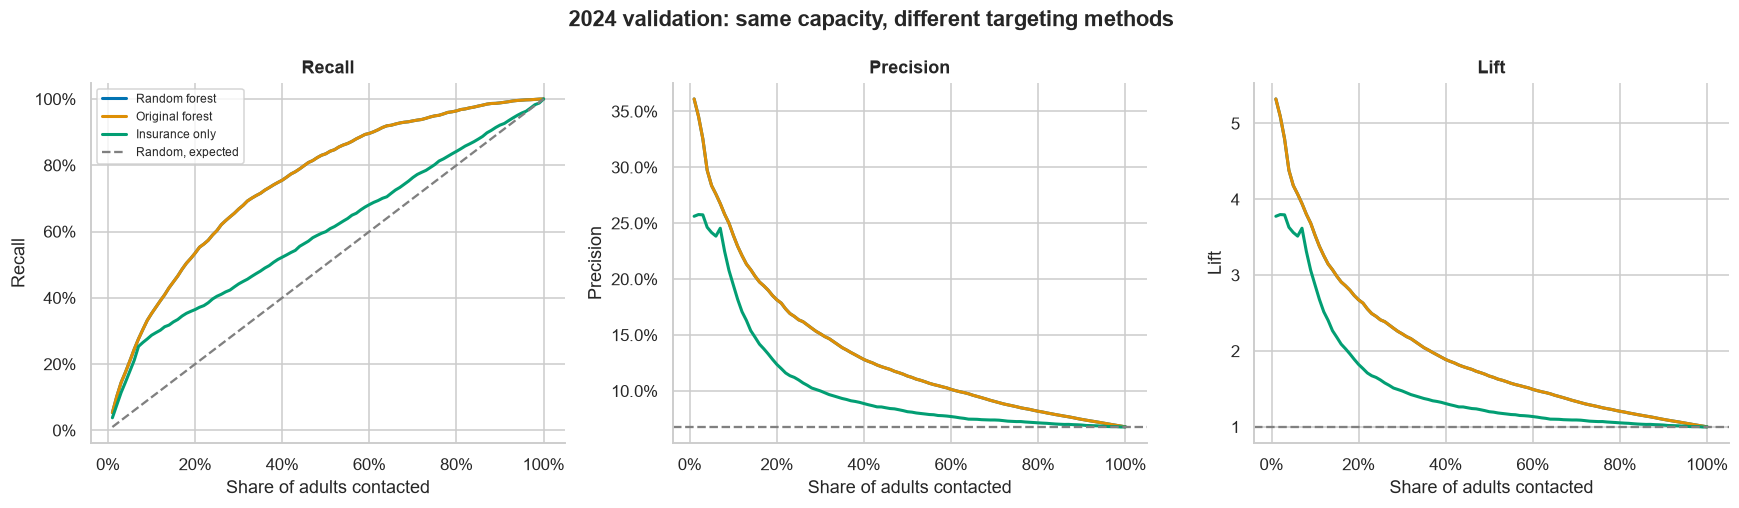

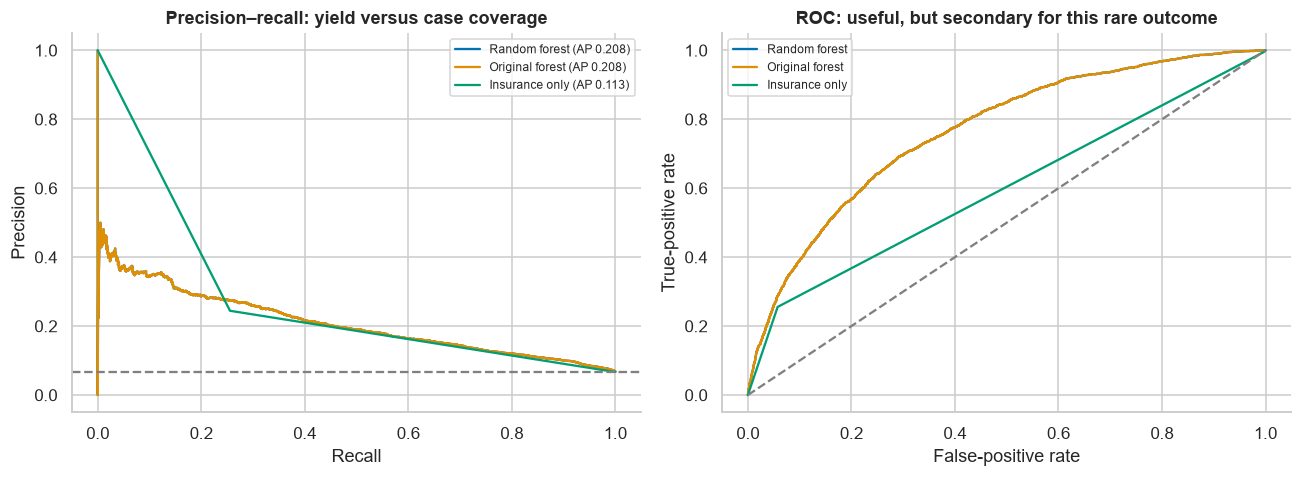

In [18]:
def plot_capacity_curves(y, score_dictionary, title):
    fractions = np.linspace(0.01, 1.0, 100)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.7))
    for name, scores in score_dictionary.items():
        metrics = pd.DataFrame([capacity_metrics(y, scores, q) for q in fractions])
        for ax, measure in zip(axes, ['recall', 'precision', 'lift']):
            ax.plot(metrics['capacity'], metrics[measure], label=name, linewidth=2)
    axes[0].plot(fractions, fractions, '--', color='grey', label='Random, expected')
    axes[1].axhline(np.mean(y), linestyle='--', color='grey')
    axes[2].axhline(1, linestyle='--', color='grey')
    for ax, measure in zip(axes, ['recall', 'precision', 'lift']):
        ax.set(xlabel='Share of adults contacted', ylabel=measure.capitalize(), title=measure.capitalize())
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        if measure != 'lift': ax.yaxis.set_major_formatter(PercentFormatter(1))
    axes[0].legend(fontsize=8)
    fig.suptitle(title, weight='bold')
    plt.tight_layout(); plt.show()

plot_capacity_curves(y_validation, {name: validation_score_dictionary[name] for name in
    ['Random forest', 'Original forest', 'Insurance only']},
    '2024 validation: same capacity, different targeting methods')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in ['Random forest', 'Original forest', 'Insurance only']:
    scores = validation_score_dictionary[name]
    precision, recall, _ = precision_recall_curve(y_validation, scores)
    axes[0].plot(recall, precision, label=f'{name} (AP {average_precision_score(y_validation, scores):.3f})')
    fpr, tpr, _ = roc_curve(y_validation, scores)
    axes[1].plot(fpr, tpr, label=name)
axes[0].axhline(y_validation.mean(), linestyle='--', color='grey')
axes[0].set(title='Precision–recall: yield versus case coverage', xlabel='Recall', ylabel='Precision')
axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], '--', color='grey')
axes[1].set(title='ROC: useful, but secondary for this rare outcome',
            xlabel='False-positive rate', ylabel='True-positive rate')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

,sample,AP,ROC_AUC,Brier
0,2023 fitted rows (optimistic),0.3211,0.8704,0.1436
1,2024 validation,0.2082,0.7653,0.1530


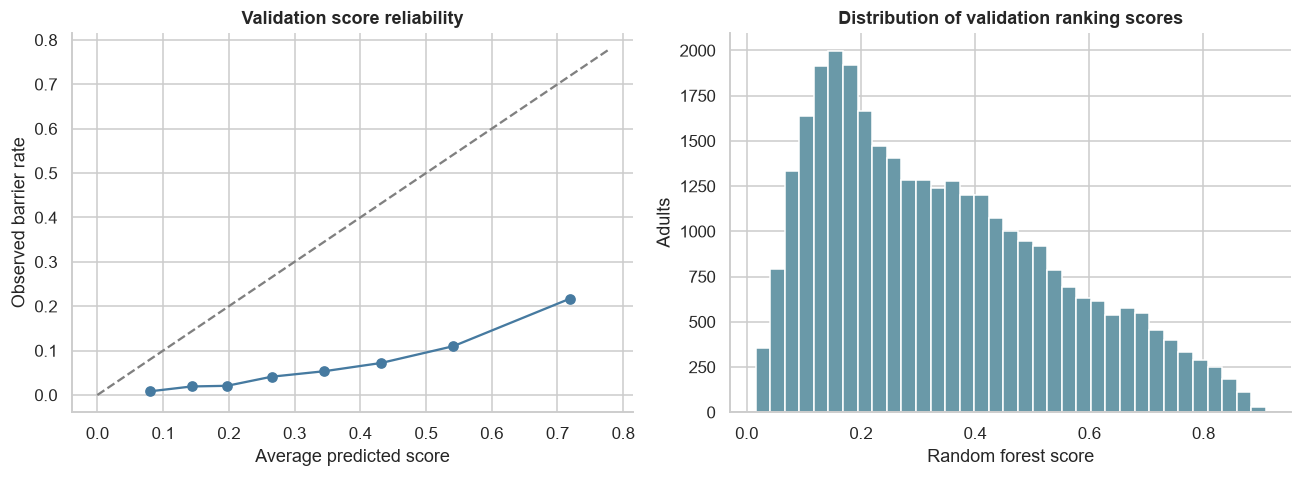

In [19]:
train_scores = selected_validation_model.predict_proba(X_train)[:, 1]
display(pd.DataFrame([
    {'sample': '2023 fitted rows (optimistic)', **overall_metrics(y_train, train_scores)},
    {'sample': '2024 validation', **overall_metrics(y_validation, selected_validation_scores)}]))
observed, predicted = calibration_curve(y_validation, selected_validation_scores, n_bins=8, strategy='quantile')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(predicted, observed, marker='o', color='#467AA0')
bound = max(max(predicted), max(observed)) * 1.08
axes[0].plot([0, bound], [0, bound], '--', color='grey')
axes[0].set(title='Validation score reliability', xlabel='Average predicted score',
            ylabel='Observed barrier rate')
axes[1].hist(selected_validation_scores, bins=35, color='#6A99A8')
axes[1].set(title='Distribution of validation ranking scores', xlabel='Random forest score', ylabel='Adults')
plt.tight_layout(); plt.show()

**Score interpretation.** In this run, observed barrier rates are lower than average forest scores in the calibration plot. Use the scores to rank adults for outreach rather than as calibrated individual probabilities. A score cutoff is an operating rule, not proof of a matching level of personal risk. Further calibration would require development data and independent evaluation.


,predictor,validation_AP_drop,shuffle_SD
9,HINOTCOVE,0.0667,0.0013
7,HEALTH,0.0448,0.0016
1,AGE,0.0349,0.0009
6,POVERTY,0.0126,0.0012
2,SEX,0.0062,0.0019
8,USUALPL,0.0040,0.0021
3,HISPRACE,0.0026,0.0007
5,EMPSTAT,0.0007,0.0006
0,REGION,0.0001,0.0015
4,EDUC,-0.0006,0.0003


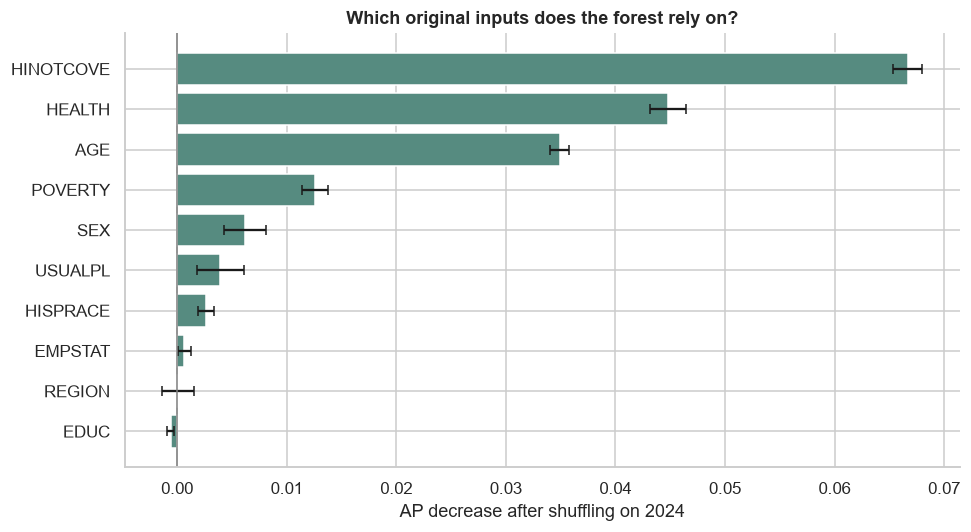

**Business interpretation.** Shuffling one original variable breaks its useful connection with other information while leaving the fitted model fixed. A larger drop means this model relies more on that variable for ranking. Here the largest drops are for **HINOTCOVE, HEALTH, AGE**. This supports checking whether those inputs are available and recorded consistently in a provider setting. Importance does not show the direction of an effect or prove causation. Correlated inputs can share information; a small drop is not proof that a characteristic never matters. Error bars show repeated shuffles, not statistical confidence intervals.

In [20]:
importance_result = permutation_importance(
    selected_validation_model, X_validation, y_validation, scoring='average_precision',
    n_repeats=4, random_state=RANDOM_STATE, n_jobs=N_JOBS)
importance_table = pd.DataFrame({'predictor': PREDICTORS,
    'validation_AP_drop': importance_result.importances_mean,
    'shuffle_SD': importance_result.importances_std}).sort_values('validation_AP_drop', ascending=False)
display(importance_table)
plot_importance = importance_table.sort_values('validation_AP_drop')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_importance['predictor'], plot_importance['validation_AP_drop'],
        xerr=plot_importance['shuffle_SD'], color='#568B80', capsize=3)
ax.axvline(0, color='grey', linewidth=1)
ax.set(title='Which original inputs does the forest rely on?', xlabel='AP decrease after shuffling on 2024')
plt.tight_layout(); plt.show()
display(Markdown('**Business interpretation.** Shuffling one original variable breaks its useful '
                 'connection with other information while leaving the fitted model fixed. A larger '
                 'drop means this model relies more on that variable for ranking. Here the largest '
                 'drops are for **' + ', '.join(importance_table.head(3)['predictor']) + '**. '
                 'This supports checking whether those inputs are available and recorded consistently '
                 'in a provider setting. Importance does not show the direction of an effect or prove '
                 'causation. Correlated inputs can share information; a small drop is not proof that '
                 'a characteristic never matters. Error bars show repeated shuffles, not statistical confidence intervals.'))

<a id="part-7-2"></a>
### 7.2 Subgroup Performance and Error Trade-offs

Assess case coverage within subgroups under the same overall 10% list,
then compare missed cases and false positives across score cutoffs.

In [21]:
def subgroup_report(records, scores, fraction):
    selected = select_top_k(scores, int(np.ceil(len(records) * fraction)))
    d = records.copy().assign(selected=selected)
    rows = []
    for column in ['HINOTCOVE', 'SEX', 'HISPRACE']:
        for value, group in d.groupby(column, dropna=False):
            tp = int(group.loc[group['selected'], 'target'].sum())
            cases = int(group['target'].sum())
            contacts = int(group['selected'].sum())
            rows.append({'variable': column, 'group': category_label(value, column), 'adults': len(group),
                          'actual_cases': cases, 'contacts': contacts, 'cases_found': tp,
                          'selection_rate': contacts / len(group),
                          'recall': tp / cases if cases else np.nan,
                          'precision': tp / contacts if contacts else np.nan})
    return pd.DataFrame(rows)

validation_subgroups = subgroup_report(validation, selected_validation_scores, 0.10)
display(validation_subgroups)
display(Markdown('**Subgroup check, illustrative 10% scenario.** The same overall contact list is '
                 'used for every group; each group is not assigned a separate quota. Group recall '
                 'shows which reported cases the procedure misses. Differences should be reviewed '
                 'alongside group sample sizes and prevalence. They are descriptive checks, not a '
                 'complete fairness assessment or a reason to infer individual need from group membership.'))

,variable,group,adults,actual_cases,contacts,cases_found,selection_rate,recall,precision
0,HINOTCOVE,Covered,29980,1625,1282,250,0.0428,0.1538,0.1950
1,HINOTCOVE,Not covered,2295,561,1952,524,0.8505,0.9340,0.2684
2,HINOTCOVE,Missing,79,9,2,0,0.0253,0.0000,0.0000
3,SEX,Male,14850,903,1310,306,0.0882,0.3389,0.2336
4,SEX,Female,17499,1292,1926,468,0.1101,0.3622,0.2430
5,SEX,Missing,5,0,0,0,0.0000,NaN,NaN
6,HISPRACE,Hispanic,4712,439,1070,250,0.2271,0.5695,0.2336
7,HISPRACE,Non-Hispanic White,21631,1350,1555,391,0.0719,0.2896,0.2514
8,HISPRACE,Non-Hispanic Black,3234,241,396,83,0.1224,0.3444,0.2096
9,HISPRACE,Non-Hispanic Asian,1851,62,63,11,0.0340,0.1774,0.1746


**Subgroup check, illustrative 10% scenario.** The same overall contact list is used for every group; each group is not assigned a separate quota. Group recall shows which reported cases the procedure misses. Differences should be reviewed alongside group sample sizes and prevalence. They are descriptive checks, not a complete fairness assessment or a reason to infer individual need from group membership.

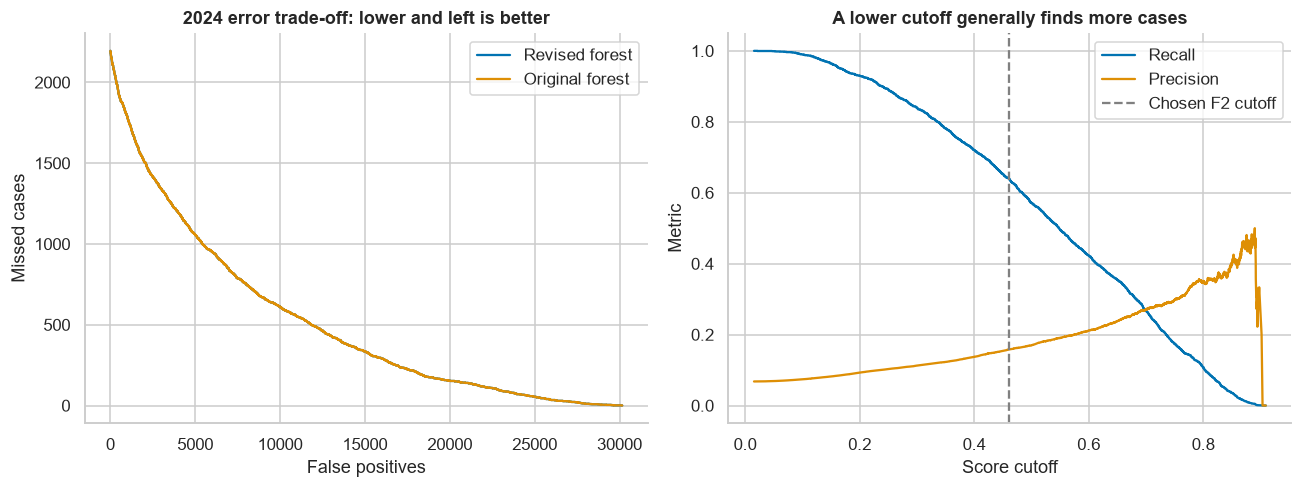

In [22]:
validation_thresholds = threshold_table(y_validation, selected_validation_scores)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(validation_thresholds['false_positives'], validation_thresholds['missed_cases'], label='Revised forest')
old_thresholds = threshold_table(y_validation, original_validation_scores)
axes[0].plot(old_thresholds['false_positives'], old_thresholds['missed_cases'], label='Original forest')
axes[0].set(xlabel='False positives', ylabel='Missed cases', title='2024 error trade-off: lower and left is better')
axes[0].legend()
axes[1].plot(validation_thresholds['cutoff'], validation_thresholds['recall'], label='Recall')
axes[1].plot(validation_thresholds['cutoff'], validation_thresholds['precision'], label='Precision')
axes[1].axvline(fixed_recall_cutoff, linestyle='--', color='grey', label='Chosen F2 cutoff')
axes[1].set(xlabel='Score cutoff', ylabel='Metric', title='A lower cutoff generally finds more cases')
axes[1].legend(); plt.tight_layout(); plt.show()

<a id="part-7-3"></a>
### 7.3 Priority-Population Profiling

Develop descriptive profiles within the random forest's highest-ranked 20% of adults in 2024. The profiles group similar characteristics and suggest follow-up questions; they do not verify an individual's support needs or establish that a particular intervention will work.


In [23]:
assert not TEST_OPENED
PROFILE_COLUMNS = ['AGE', 'POVERTY', 'HEALTH', 'HINOTCOVE', 'USUALPL', 'EMPSTAT', 'EDUC']
PROFILE_CATS = PROFILE_COLUMNS[1:]
PROFILE_CAT_INDEX = list(range(1, len(PROFILE_COLUMNS)))
assert set(PROFILE_COLUMNS).isdisjoint(EXCLUDED + ['score'])
planning_mask = select_top_k(selected_validation_scores, int(np.ceil(PROFILE_FRACTION * len(validation))))
planning_pool = validation.loc[planning_mask].copy().reset_index(drop=True)
profile_age_imputer = SimpleImputer(strategy='median')
profile_age_scaler = StandardScaler()
profile_age = profile_age_scaler.fit_transform(profile_age_imputer.fit_transform(planning_pool[['AGE']]))
FIT_LOG.append({'step': 'Profile age imputer and scaler', 'years': [2024], 'rows': len(planning_pool)})

def profile_matrix(records):
    age = profile_age_scaler.transform(profile_age_imputer.transform(records[['AGE']])).ravel()
    cats = records[PROFILE_CATS].fillna(-1).astype(int).astype(str).to_numpy()
    matrix = np.empty((len(records), len(PROFILE_COLUMNS)), dtype=object)
    matrix[:, 0] = age
    matrix[:, 1:] = cats
    return matrix

planning_matrix = profile_matrix(planning_pool)
rng = np.random.default_rng(RANDOM_STATE)
silhouette_idx = rng.choice(len(planning_pool), min(800, len(planning_pool)), replace=False)
small_matrix = planning_matrix[silhouette_idx]
small_age = small_matrix[:, 0].astype(float)
profile_distance = (small_age[:, None] - small_age[None, :]) ** 2
for j in PROFILE_CAT_INDEX:
    profile_distance += 0.5 * (small_matrix[:, j, None] != small_matrix[None, :, j])
np.fill_diagonal(profile_distance, 0.0)

cluster_candidates, cluster_rows = {}, []
for k in range(2, 6):
    model = KPrototypes(n_clusters=k, init='Huang', n_init=3, max_iter=40,
                        gamma=0.5, random_state=RANDOM_STATE, n_jobs=1, verbose=0)
    labels = model.fit_predict(planning_matrix, categorical=PROFILE_CAT_INDEX)
    FIT_LOG.append({'step': f'Profile k={k}', 'years': [2024], 'rows': len(planning_pool)})
    repeat_labels = []
    for seed in [17, 41]:
        repeat = KPrototypes(n_clusters=k, init='Huang', n_init=2, max_iter=40,
                             gamma=0.5, random_state=seed, n_jobs=1, verbose=0)
        repeat_labels.append(repeat.fit_predict(planning_matrix, categorical=PROFILE_CAT_INDEX))
        FIT_LOG.append({'step': f'Profile stability k={k}, seed={seed}', 'years': [2024], 'rows': len(planning_pool)})
    stability = np.mean([adjusted_rand_score(labels, repeat) for repeat in repeat_labels])
    sizes = np.bincount(labels, minlength=k) / len(labels)
    silhouette = silhouette_score(profile_distance, labels[silhouette_idx], metric='precomputed')
    cluster_candidates[k] = model
    cluster_rows.append({'k': k, 'silhouette': silhouette, 'start_stability_ARI': stability,
                         'smallest_share': sizes.min(), 'within_cluster_cost': model.cost_})
cluster_diagnostics = pd.DataFrame(cluster_rows)
eligible = cluster_diagnostics.loc[(cluster_diagnostics['smallest_share'] >= 0.05) &
                                    (cluster_diagnostics['start_stability_ARI'] >= 0.60)]
profiles_stable = not eligible.empty
if eligible.empty:
    eligible = cluster_diagnostics.copy()
best_silhouette = eligible['silhouette'].max()
chosen_k = int(eligible.loc[eligible['silhouette'] >= best_silhouette - 0.02, 'k'].min())
profile_model = cluster_candidates[chosen_k]
planning_clusters = profile_model.predict(planning_matrix, categorical=PROFILE_CAT_INDEX)
cluster_age_order = planning_pool.assign(cluster=planning_clusters).groupby('cluster')['AGE'].mean().sort_values().index
PROFILE_NAMES = {int(cluster): f'Profile {chr(65+i)}' for i, cluster in enumerate(cluster_age_order)}
display(cluster_diagnostics)
print(f'Planning adults: {len(planning_pool):,}; chosen clusters: {chosen_k}; stability screen passed: {profiles_stable}')

,k,silhouette,start_stability_ARI,smallest_share,within_cluster_cost
0,2,0.4821,0.9597,0.4302,"11,813.5170"
1,3,0.3173,0.6943,0.2811,"10,635.0964"
2,4,0.1963,0.6677,0.2106,"9,935.3818"
3,5,0.1682,0.4324,0.1225,"9,619.1243"


Planning adults: 6,471; chosen clusters: 2; stability screen passed: True


,profile,adults,share,median_age,uninsured,income_below_2x_poverty,fair_or_poor_health,no_usual_place,not_employed,reported_barrier_rate
0,Profile A,3687,0.5698,33.0000,0.4125,0.5053,0.2129,0.2967,0.1996,0.1874
1,Profile B,2784,0.4302,57.0000,0.2640,0.5855,0.5909,0.1480,0.5097,0.1735


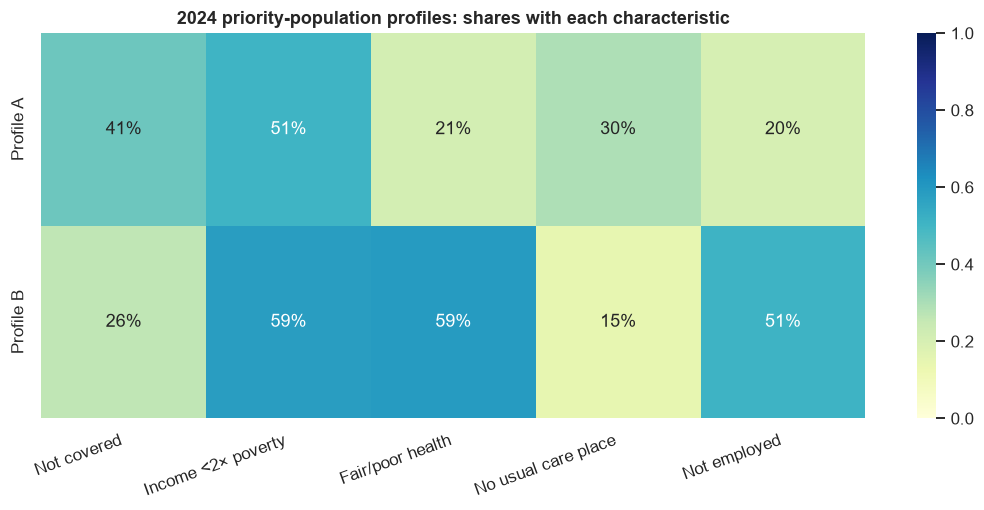

,profile,possible_outreach_focus
0,Profile A,Ask about current cost barriers and explain available assistance pathways. Explore help connecting to a regular source of care.
1,Profile B,Review cost concerns alongside care navigation and existing coverage. Coordinate follow-up with the existing care team where appropriate.


In [24]:
LOWER_INCOME_CODES = [11, 12, 13, 21, 22, 23, 24]

def profile_summary(records, cluster_labels):
    data = records.assign(profile=[PROFILE_NAMES[int(c)] for c in cluster_labels])
    rows = []
    for name, g in data.groupby('profile'):
        rows.append({'profile': name, 'adults': len(g), 'share': len(g) / len(data),
                      'median_age': g['AGE'].median(),
                      'uninsured': g['HINOTCOVE'].eq(2).mean(),
                      'income_below_2x_poverty': g['POVERTY'].isin(LOWER_INCOME_CODES).mean(),
                      'fair_or_poor_health': g['HEALTH'].isin([4, 5]).mean(),
                      'no_usual_place': g['USUALPL'].eq(1).mean(),
                      'not_employed': g['EMPSTAT'].eq(200).mean(),
                      'reported_barrier_rate': g['target'].mean()})
    return pd.DataFrame(rows)

planning_profile_summary = profile_summary(planning_pool, planning_clusters)
display(planning_profile_summary)
profile_plot_columns = ['uninsured', 'income_below_2x_poverty', 'fair_or_poor_health',
                         'no_usual_place', 'not_employed']
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(planning_profile_summary.set_index('profile')[profile_plot_columns],
            annot=True, fmt='.0%', cmap='YlGnBu', vmin=0, vmax=1, ax=ax)
ax.set(title='2024 priority-population profiles: shares with each characteristic', xlabel='', ylabel='')
ax.set_xticklabels(['Not covered', 'Income <2× poverty', 'Fair/poor health',
                    'No usual care place', 'Not employed'], rotation=20, ha='right')
plt.tight_layout(); plt.show()

def support_hypotheses(summary):
    rows = []
    for _, r in summary.iterrows():
        if r['uninsured'] >= 0.5:
            suggestion = 'Check coverage/enrolment options and financial-assistance needs.'
        elif r['fair_or_poor_health'] >= 0.4:
            suggestion = 'Review cost concerns alongside care navigation and existing coverage.'
        else:
            suggestion = 'Ask about current cost barriers and explain available assistance pathways.'
        if r['no_usual_place'] >= 0.20:
            suggestion += ' Explore help connecting to a regular source of care.'
        else:
            suggestion += ' Coordinate follow-up with the existing care team where appropriate.'
        rows.append({'profile': r['profile'], 'possible_outreach_focus': suggestion})
    return pd.DataFrame(rows)

support_table = support_hypotheses(planning_profile_summary)
display(support_table)

The saved clustering comparison selects **two profiles** from **6,471** prioritised 2024 adults, with silhouette **0.4821** and mean starting-seed stability ARI **0.9597**. Profile A contains **3,687** adults (median age **33**); Profile B contains **2,784** (median age **57**).

**Profile percentage denominator.** Characteristic percentages use all adults in each profile as the denominator. Missing responses remain in that denominator but are not counted as having the characteristic. A missing answer does not establish that the characteristic is absent.


<a id="part-7-4"></a>
### 7.4 Final Random Forest Refit and Procedure Freeze

Refit the selected forest and operational baselines using 2023–2024 and
record the fitted procedures, settings, cutoffs and profile definitions as fixed choices. The logistic benchmark
has already been refitted and fixed in Part 6.3.2.


In [25]:
assert not TEST_OPENED
X_development, y_development = development[PREDICTORS], development['target']
final_model = clone(selected_validation_model)
final_original = clone(original_validation_model)
final_insurance = clone(insurance_validation_model)
final_constant = clone(constant_validation_model)
fit_development(final_model, X_development, y_development, development, 'FINAL revised forest: 2023–2024')
fit_development(final_original, X_development, y_development, development, 'FINAL original forest: 2023–2024')
fit_development(final_insurance, X_development, y_development, development, 'FINAL insurance baseline: 2023–2024')
fit_development(final_constant, X_development, y_development, development, 'FINAL constant baseline: 2023–2024')
frozen_choices = {'predictors': PREDICTORS, 'candidate': selected_forest_name,
    'forest_parameters': final_model.named_steps['model'].get_params(),
    'selection': '2023 five-fold AP screen, 2024 F2 selection',
    'recall_first_cutoff': fixed_recall_cutoff, 'conservative_cutoff': fixed_conservative_cutoff,
    'original_f2_cutoff': original_fixed_cutoff, 'ordered_code_maps': ORDER_MAPS,
    'capacities': list(CAPACITIES), 'profile_k': chosen_k, 'profile_columns': PROFILE_COLUMNS,
    'profile_planning_fraction': PROFILE_FRACTION, 'profile_names': PROFILE_NAMES, 'tie_seed': RANDOM_STATE}
def freeze_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()
CHOICE_DIGEST = freeze_digest(frozen_choices)
import pickle
fitted_state_digest = hashlib.sha256(pickle.dumps((final_model, final_original, final_insurance,
    final_constant, profile_age_imputer, profile_age_scaler, profile_model))).hexdigest()
FITS_BEFORE_TEST = len(FIT_LOG)
display(pd.DataFrame(FIT_LOG))
print('All models, cutoffs and profile definitions are fixed before opening 2025.')

,step,years,rows
0,Original forest reference: 2023,[2023],29276
1,One-hot: 2023 five-fold search,[2023],29276
2,One-hot finalist 1: 2023 fit,[2023],29276
3,One-hot finalist 2: 2023 fit,[2023],29276
4,Ordered: 2023 five-fold search,[2023],29276
5,Ordered finalist 1: 2023 fit,[2023],29276
6,Ordered finalist 2: 2023 fit,[2023],29276
7,Hybrid: 2023 five-fold search,[2023],29276
8,Hybrid finalist 1: 2023 fit,[2023],29276
9,Hybrid finalist 2: 2023 fit,[2023],29276


All models, cutoffs and profile definitions are fixed before opening 2025.


In this saved run, the selected forest is the original one-hot reference. The log retains the label “FINAL revised forest” for the selected-model procedure; it and “FINAL original forest” refit the same retained one-hot specification.

<a id="part-8"></a>
## Part 8: Final Out-of-Time Evaluation on 2025 Data

<a id="part-8-1"></a>
### 8.1 Random Forest Performance and Outreach Trade-offs

Load the 2025 sample and apply the models and operating rules fixed during development. Equal-capacity lists compare targeting under the same contact limit. The separate F2 rules prioritise case finding and can produce larger contact lists; their results should be interpreted alongside workload and false positives.


In [26]:
assert not TEST_OPENED
if not TEST_PATH.exists():
    raise FileNotFoundError('Place nhis_2025.csv beside the notebook.')
TEST_OPENED = True
evaluation_raw = pd.read_csv(TEST_PATH, dtype={'NHISPID': str})
verify_structure(evaluation_raw, {2025}, 'Evaluation file')
evaluation = prepare_nhis(evaluation_raw)
assert evaluation['NHISPID'].is_unique and evaluation['NHISPID'].notna().all()
assert set(development['NHISPID']).isdisjoint(evaluation['NHISPID'])
assert evaluation['AGE'].dropna().between(18, 85).all()
X_evaluation, y_evaluation = evaluation[PREDICTORS], evaluation['target']
evaluation_scores = final_model.predict_proba(X_evaluation)[:, 1]
insurance_scores = final_insurance.predict_proba(X_evaluation)[:, 1]
constant_scores = final_constant.predict_proba(X_evaluation)[:, 1]
evaluation_score_dictionary = {'Random forest': evaluation_scores,
    'Insurance only': insurance_scores, 'Constant score / random tie order': constant_scores}
display(cleaning_summary(evaluation_raw, evaluation))
display(pd.DataFrame({'adults': [len(evaluation)], 'reported_cases': [int(y_evaluation.sum())],
                      'sample_prevalence': [y_evaluation.mean()],
                      'weighted_prevalence': [weighted_binary_rate(evaluation)]}))

evaluation_metrics = pd.DataFrame([{'method': name, **overall_metrics(y_evaluation, scores)}
                                  for name, scores in evaluation_score_dictionary.items()])
evaluation_capacity_table = table_at_capacities(y_evaluation, evaluation_score_dictionary)
random_expected = []
for q in CAPACITIES:
    k = int(np.ceil(q * len(y_evaluation)))
    random_expected.append({'method': 'Random selection: expected', 'capacity': q, 'contacts': k,
        'cases_found': k * y_evaluation.mean(), 'precision': y_evaluation.mean(),
        'recall': k / len(y_evaluation), 'lift': 1.0})
random_expected = pd.DataFrame(random_expected)
display(evaluation_metrics)
display(evaluation_capacity_table[['method', 'capacity', 'contacts', 'cases_found',
    'precision', 'recall', 'lift', 'missed_cases', 'false_positives']])
display(random_expected)

original_evaluation_scores = final_original.predict_proba(X_evaluation)[:, 1]
evaluation_score_dictionary['Original forest'] = original_evaluation_scores
evaluation_capacity_table = table_at_capacities(y_evaluation, evaluation_score_dictionary)
recall_first_predictions = evaluation_scores >= fixed_recall_cutoff
conservative_predictions = evaluation_scores >= fixed_conservative_cutoff
original_f2_predictions = original_evaluation_scores >= original_fixed_cutoff
original_10_predictions = select_top_k(original_evaluation_scores, int(np.ceil(0.10 * len(evaluation))))
operating_results = pd.DataFrame([
    {'procedure': 'Original forest: illustrative 10% list', **binary_metrics(y_evaluation, original_10_predictions)},
    {'procedure': 'Original forest: F2 cutoff', **binary_metrics(y_evaluation, original_f2_predictions)},
    {'procedure': 'Revised forest: F2 cutoff', **binary_metrics(y_evaluation, recall_first_predictions)},
    {'procedure': 'Revised forest: conservative cutoff', **binary_metrics(y_evaluation, conservative_predictions)}])
print('Primary error-count comparison — all decision rules were frozen on 2024:')
display(operating_results)


,stage,rows
0,Raw records,30264
1,Sample adults,24215
2,Valid adult target,24018
3,Retained after positive-weight check,24018


,adults,reported_cases,sample_prevalence,weighted_prevalence
0,24018,1351,0.0562,0.0608


,method,AP,ROC_AUC,Brier
0,Random forest,0.2267,0.7919,0.1517
1,Insurance only,0.1113,0.6190,0.0506
2,Constant score / random tie order,0.0562,0.5000,0.0531


,method,capacity,contacts,cases_found,precision,recall,lift,missed_cases,false_positives
0,Random forest,0.0500,1201,346,0.2881,0.2561,5.1217,1005,855
1,Random forest,0.1000,2402,559,0.2327,0.4138,4.1373,792,1843
2,Random forest,0.2000,4804,794,0.1653,0.5877,2.9383,557,4010
3,Random forest,0.3000,7206,951,0.1320,0.7039,2.3462,400,6255
4,Random forest,0.4000,9608,1081,0.1125,0.8001,2.0002,270,8527
5,Random forest,0.5000,12009,1174,0.0978,0.8690,1.7380,177,10835
6,Insurance only,0.0500,1201,282,0.2348,0.2087,4.1743,1069,919
7,Insurance only,0.1000,2402,434,0.1807,0.3212,3.2122,917,1968
8,Insurance only,0.2000,4804,550,0.1145,0.4071,2.0354,801,4254
9,Insurance only,0.3000,7206,649,0.0901,0.4804,1.6011,702,6557


,method,capacity,contacts,cases_found,precision,recall,lift
0,Random selection: expected,0.0500,1201,67.5556,0.0562,0.0500,1.0000
1,Random selection: expected,0.1000,2402,135.1112,0.0562,0.1000,1.0000
2,Random selection: expected,0.2000,4804,270.2225,0.0562,0.2000,1.0000
3,Random selection: expected,0.3000,7206,405.3337,0.0562,0.3000,1.0000
4,Random selection: expected,0.4000,9608,540.4450,0.0562,0.4000,1.0000
5,Random selection: expected,0.5000,12009,675.5000,0.0562,0.5000,1.0000


Primary error-count comparison — all decision rules were frozen on 2024:


,procedure,cases_found,missed_cases,false_positives,true_negatives,flagged,precision,recall,F2
0,Original forest: illustrative 10% list,559,792,1843,20824,2402,0.2327,0.4138,0.3581
1,Original forest: F2 cutoff,918,433,5675,16992,6593,0.1392,0.6795,0.3826
2,Revised forest: F2 cutoff,918,433,5675,16992,6593,0.1392,0.6795,0.3826
3,Revised forest: conservative cutoff,540,811,1717,20950,2257,0.2393,0.3997,0.3524


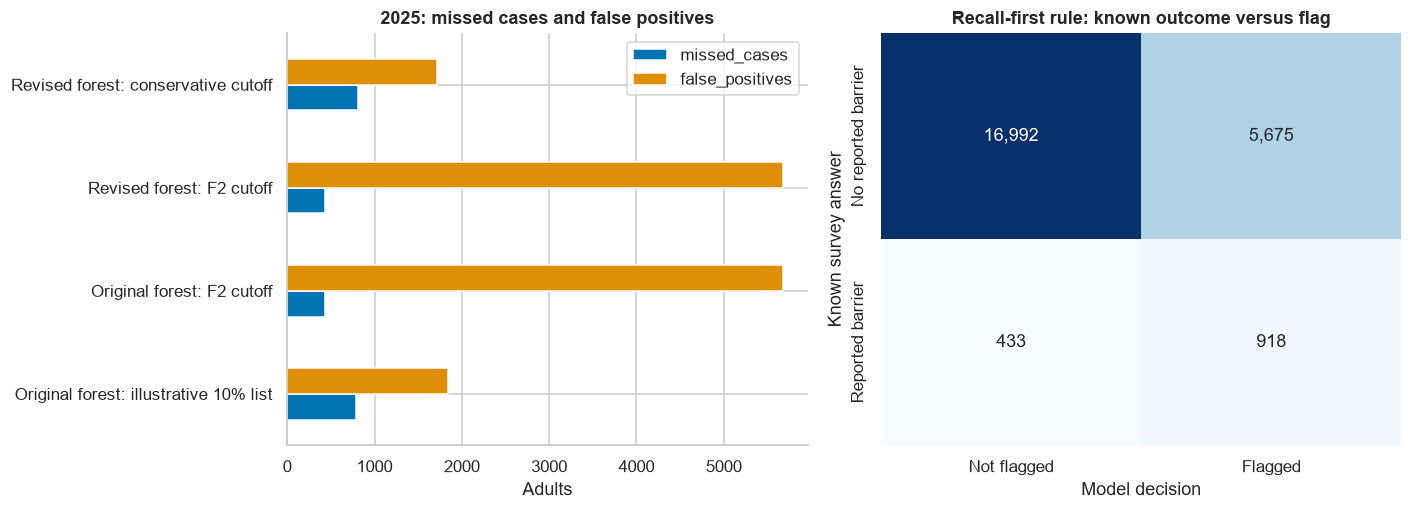

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
operating_results.set_index('procedure')[['missed_cases', 'false_positives']].plot.barh(ax=axes[0])
axes[0].set(title='2025: missed cases and false positives', xlabel='Adults', ylabel='')
matrix = confusion_matrix(y_evaluation, recall_first_predictions.astype(int), labels=[0, 1])
sns.heatmap(matrix, annot=True, fmt=',d', cbar=False, cmap='Blues', ax=axes[1],
    xticklabels=['Not flagged', 'Flagged'], yticklabels=['No reported barrier', 'Reported barrier'])
axes[1].set(title='Recall-first rule: known outcome versus flag', xlabel='Model decision', ylabel='Known survey answer')
plt.tight_layout(); plt.show()
new_point = operating_results.iloc[2]
old_point = operating_results.iloc[0]
old_f2_point = operating_results.iloc[1]
conservative_point = operating_results.iloc[3]

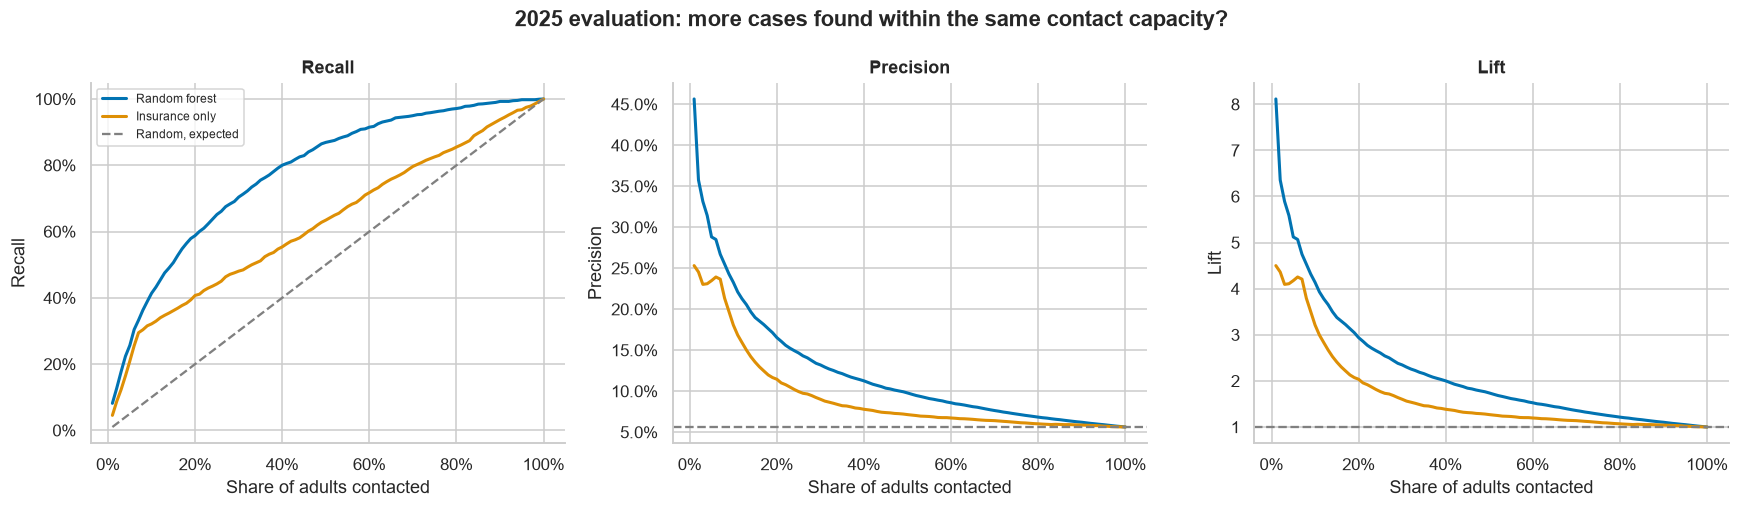

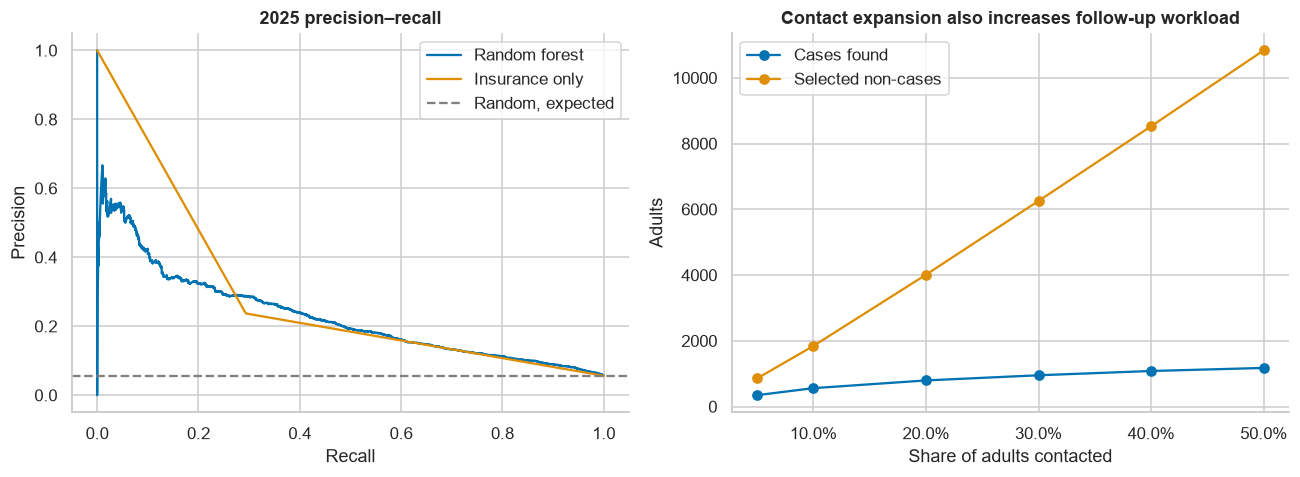

In [28]:
plot_capacity_curves(y_evaluation, {'Random forest': evaluation_scores, 'Insurance only': insurance_scores},
                     '2025 evaluation: more cases found within the same contact capacity?')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, scores in [('Random forest', evaluation_scores), ('Insurance only', insurance_scores)]:
    precision, recall, _ = precision_recall_curve(y_evaluation, scores)
    axes[0].plot(recall, precision, label=name)
axes[0].axhline(y_evaluation.mean(), color='grey', linestyle='--', label='Random, expected')
axes[0].set(title='2025 precision–recall', xlabel='Recall', ylabel='Precision')
axes[0].legend()
rf_capacity = evaluation_capacity_table.loc[evaluation_capacity_table['method'].eq('Random forest')]
axes[1].plot(rf_capacity['capacity'], rf_capacity['cases_found'], marker='o', label='Cases found')
axes[1].plot(rf_capacity['capacity'], rf_capacity['false_positives'], marker='o', label='Selected non-cases')
axes[1].set(title='Contact expansion also increases follow-up workload',
            xlabel='Share of adults contacted', ylabel='Adults')
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()
plt.tight_layout(); plt.show()

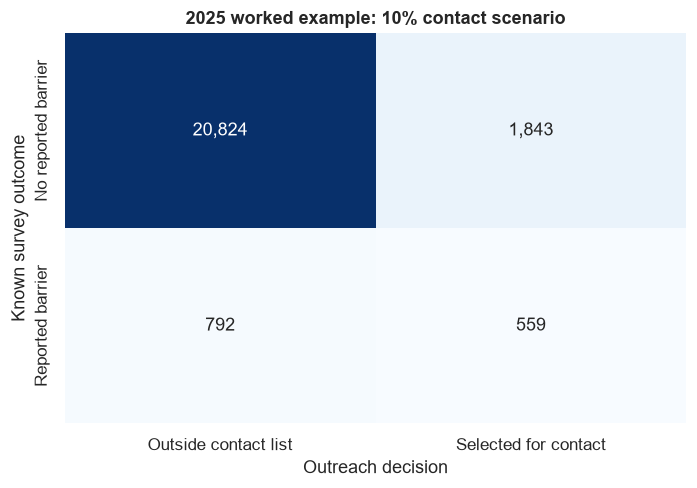

In [29]:
example_q = 0.10  # Worked example only, not the provider's established budget.
example_rf = capacity_metrics(y_evaluation, evaluation_scores, example_q)
example_insurance = capacity_metrics(y_evaluation, insurance_scores, example_q)
example_selected = select_top_k(evaluation_scores, example_rf['contacts'])
example_matrix = confusion_matrix(y_evaluation, example_selected.astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(6.5, 4.6))
sns.heatmap(example_matrix, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Outside contact list', 'Selected for contact'],
            yticklabels=['No reported barrier', 'Reported barrier'])
ax.set(title='2025 worked example: 10% contact scenario', xlabel='Outreach decision', ylabel='Known survey outcome')
plt.tight_layout(); plt.show()

**Evaluation results and saved labels.** “Revised forest” denotes the selected-model procedure in the existing tables and charts. Here that procedure retained **Original forest reference**, so the original-F2 and revised-F2 rows are identical; they are not evidence of improvement from a different forest. The 10% list selects **2,402** adults and finds **559** cases. The F2 rule selects **6,593** adults and finds **918** cases; the conservative rule selects **2,257** and finds **540**.

Record checks confirm that the evaluation identifiers are unique and do not overlap with development identifiers.

<a id="part-8-2"></a>
### 8.2 Applying the Development Profiles to 2025

Assign the forest's highest-ranked 20% of adults in 2025 to the fixed profiles developed on 2024. Keep the profile definitions unchanged and summarise the characteristics of this selected population.


,profile,adults,share,median_age,uninsured,income_below_2x_poverty,fair_or_poor_health,no_usual_place,not_employed,reported_barrier_rate
0,Profile A,2721,0.5664,34.0000,0.3907,0.4087,0.1944,0.2870,0.1635,0.1687
1,Profile B,2083,0.4336,57.0000,0.2520,0.5146,0.5458,0.1359,0.4772,0.1608


capacity,0.1000,0.2000,0.3000
profile,,,
Profile A,0.6137,0.5664,0.5472
Profile B,0.3863,0.4336,0.4528


,profile,possible_outreach_focus
0,Profile A,Ask about current cost barriers and explain available assistance pathways. Explore help connecting to a regular source of care.
1,Profile B,Review cost concerns alongside care navigation and existing coverage. Coordinate follow-up with the existing care team where appropriate.


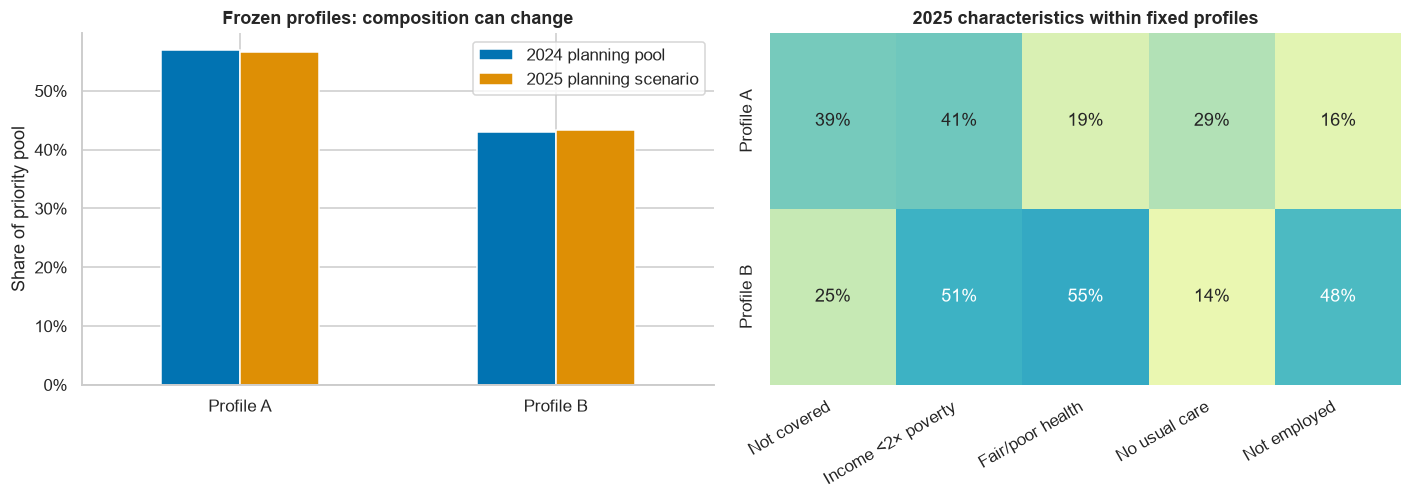

In [30]:
evaluation_profile_rows, profile_shares = [], []
for q in [0.10, 0.20, 0.30]:
    mask = select_top_k(evaluation_scores, int(np.ceil(q * len(evaluation))))
    selected_records = evaluation.loc[mask].copy()
    labels = profile_model.predict(profile_matrix(selected_records), categorical=PROFILE_CAT_INDEX)
    summary = profile_summary(selected_records, labels)
    profile_shares.append(summary[['profile', 'share']].assign(capacity=q))
    if np.isclose(q, PROFILE_FRACTION):
        evaluation_profile_summary = summary
        evaluation_profile_records = selected_records
        evaluation_profile_labels = labels
display(evaluation_profile_summary)
display(pd.concat(profile_shares).pivot(index='profile', columns='capacity', values='share'))
display(support_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
shares_plot = pd.DataFrame({
    '2024 planning pool': planning_profile_summary.set_index('profile')['share'],
    '2025 planning scenario': evaluation_profile_summary.set_index('profile')['share']}).fillna(0)
shares_plot.plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Frozen profiles: composition can change', ylabel='Share of priority pool', xlabel='')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
sns.heatmap(evaluation_profile_summary.set_index('profile')[profile_plot_columns],
            annot=True, fmt='.0%', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set(title='2025 characteristics within fixed profiles', xlabel='', ylabel='')
axes[1].set_xticklabels(['Not covered', 'Income <2× poverty', 'Fair/poor health',
                         'No usual care', 'Not employed'], rotation=30, ha='right')
plt.tight_layout(); plt.show()

The saved 2025 top-20% pool contains **4,804** adults: **2,721** in Profile A (**56.6%**, median age **34**) and **2,083** in Profile B (**43.4%**, median age **57**).

**Profile percentage denominator.** Characteristic percentages use all adults in each profile as the denominator. Missing responses remain in that denominator but are not counted as having the characteristic. A missing answer does not establish that the characteristic is absent.


In [31]:
flagged_records = evaluation.loc[recall_first_predictions].copy()
flagged_clusters = profile_model.predict(profile_matrix(flagged_records), categorical=PROFILE_CAT_INDEX)
flagged_profile_summary = profile_summary(flagged_records, flagged_clusters)
print('Fixed development profiles applied to the broader recall-first flagged group:')
display(flagged_profile_summary)

Fixed development profiles applied to the broader recall-first flagged group:


,profile,adults,share,median_age,uninsured,income_below_2x_poverty,fair_or_poor_health,no_usual_place,not_employed,reported_barrier_rate
0,Profile A,3626,0.5500,34.0000,0.2951,0.3822,0.1630,0.2568,0.1649,0.1420
1,Profile B,2967,0.4500,57.0000,0.1813,0.4850,0.5035,0.1200,0.4742,0.1358


The separate F2 list contains **6,593** adults: **3,626** in A and **2,967** in B. These use the same fixed profiles but different selection rules.

**Profile percentage denominator.** Characteristic percentages use all adults in each profile as the denominator. Missing responses remain in that denominator but are not counted as having the characteristic. A missing answer does not establish that the characteristic is absent.


<a id="part-8-3"></a>
### 8.3 Random Forest versus Full-Feature Logistic Regression

Compare the fixed models on the same 2025 sample at equal contact capacities and their separate 2024 F2 cutoffs. Report ranking, case detection and workload without further tuning. F2 lists may differ in size.


In [32]:
assert TEST_OPENED, "Run Part 8.1 before the benchmark evaluation in Part 8.3."
assert set(evaluation["YEAR"]) == {2025}
assert "rfcomp_final_lr" in globals(), "Run the benchmark development in Part 6.3 before Part 8."
rfcomp_original_evaluation_snapshot = __import__("pickle").dumps(
    (
        evaluation,
        X_evaluation,
        y_evaluation,
        selected_forest_name,
        fixed_recall_cutoff,
        fixed_conservative_cutoff,
        original_fixed_cutoff,
        evaluation_scores,
        insurance_scores,
        constant_scores,
        evaluation_metrics,
        evaluation_capacity_table,
        operating_results,
        FIT_LOG,
        CHOICE_DIGEST,
        fitted_state_digest,
    )
)
rfcomp_evaluation_lr_scores = rfcomp_final_lr.predict_proba(X_evaluation)[:, 1]
rfcomp_evaluation_dictionary = {
    "Existing random forest": evaluation_scores,
    "Full-feature logistic": rfcomp_evaluation_lr_scores,
    "Insurance only": insurance_scores,
    "Constant score / random ties": constant_scores,
}
rfcomp_evaluation_metrics = pd.DataFrame(
    [
        {"method": name, **overall_metrics(y_evaluation, scores)}
        for name, scores in rfcomp_evaluation_dictionary.items()
    ]
)
rfcomp_display(
    rfcomp_evaluation_metrics,
    "Table 8.3.1: Later-year ranking and probability error.",
)
rfcomp_evaluation_capacity = table_at_capacities(
    y_evaluation, rfcomp_evaluation_dictionary
)
rfcomp_capacity_example = rfcomp_evaluation_capacity.loc[
    np.isclose(rfcomp_evaluation_capacity["capacity"], 0.10)
].copy()
rfcomp_display(
    rfcomp_capacity_example,
    "Table 8.3.2: Later-year methods at exactly the same 10% capacity.",
)
rfcomp_display(
    rfcomp_evaluation_capacity,
    "Table 8.3.3: Later-year comparison across all declared capacities.",
)
rfcomp_evaluation_rules = pd.DataFrame(
    [
        {
            "method": "Existing random forest",
            "cutoff": fixed_recall_cutoff,
            **binary_metrics(y_evaluation, evaluation_scores >= fixed_recall_cutoff),
        },
        {
            "method": "Full-feature logistic",
            "cutoff": rfcomp_lr_cutoff,
            **binary_metrics(
                y_evaluation, rfcomp_evaluation_lr_scores >= rfcomp_lr_cutoff
            ),
        },
    ]
)
rfcomp_evaluation_rules["selected_share"] = rfcomp_evaluation_rules["flagged"] / len(
    evaluation
)
rfcomp_display(
    rfcomp_evaluation_rules,
    "Table 8.3.4: Frozen F2 rules; contact counts can differ.",
)


def rfcomp_interpret(capacity_table, operating_table):
    """Explain calculated differences without changing or reselecting procedures."""
    equal = capacity_table.set_index("method")
    forest = equal.loc["Existing random forest"]
    logistic = equal.loc["Full-feature logistic"]
    insurance = equal.loc["Insurance only"]
    rules = operating_table.set_index("method")
    forest_rule = rules.loc["Existing random forest"]
    logistic_rule = rules.loc["Full-feature logistic"]

    difference = int(forest["cases_found"] - logistic["cases_found"])
    relation = (
        "the same number of cases as"
        if difference == 0
        else f'{abs(difference):,} {"more" if difference > 0 else "fewer"} cases than'
    )

    display(
        Markdown(
            f'**10% capacity ({int(forest["contacts"]):,} adults):** forest '
            f'{int(forest["cases_found"]):,}, logistic '
            f'{int(logistic["cases_found"]):,}, and insurance-only '
            f'{int(insurance["cases_found"]):,} reported cases identified. '
            f'The forest finds {relation} logistic regression.'
        )
    )
    display(
        Markdown(
            f'**Fixed F2 rules:** forest identifies {int(forest_rule["cases_found"]):,} cases '
            f'from {int(forest_rule["flagged"]):,} flags (F2 {forest_rule["F2"]:.4f}); '
            f'logistic identifies {int(logistic_rule["cases_found"]):,} cases '
            f'from {int(logistic_rule["flagged"]):,} flags (F2 {logistic_rule["F2"]:.4f}). '
            'Compare workload alongside F2.'
        )
    )
    display(
        Markdown(
            '**Interpretation:** assess any improvement against workload and score reliability. '
            'Small differences need independent confirmation; flags require a current-needs assessment.'
        )
    )


rfcomp_interpret(rfcomp_capacity_example, rfcomp_evaluation_rules)
rfcomp_checks = {
    "Equal-capacity methods select the same number": rfcomp_capacity_example[
        "contacts"
    ].nunique()
    == 1,
    "Existing RF capacity rows are reproduced": all(
        capacity_metrics(y_evaluation, evaluation_scores, q)
        == rfcomp_evaluation_capacity.loc[
            rfcomp_evaluation_capacity["method"].eq("Existing random forest")
            & np.isclose(rfcomp_evaluation_capacity["capacity"], q)
        ]
        .drop(columns="method")
        .iloc[0]
        .to_dict()
        for q in CAPACITIES
    ),
    "Fixed logistic choices are unchanged": hashlib.sha256(
        json.dumps(rfcomp_frozen, sort_keys=True, default=str).encode()
    ).hexdigest()
    == rfcomp_frozen_digest,
    "Added fitted logistic model is unchanged": hashlib.sha256(
        __import__("pickle").dumps(rfcomp_final_lr)
    ).hexdigest()
    == rfcomp_lr_state_digest,
    "Existing evaluation results and settings are unchanged": __import__(
        "pickle"
    ).dumps(
        (
            evaluation,
            X_evaluation,
            y_evaluation,
            selected_forest_name,
            fixed_recall_cutoff,
            fixed_conservative_cutoff,
            original_fixed_cutoff,
            evaluation_scores,
            insurance_scores,
            constant_scores,
            evaluation_metrics,
            evaluation_capacity_table,
            operating_results,
            FIT_LOG,
            CHOICE_DIGEST,
            fitted_state_digest,
        )
    )
    == rfcomp_original_evaluation_snapshot,
}
rfcomp_display(
    pd.Series(rfcomp_checks, name="passed").rename_axis("check").reset_index(),
    "Table 8.3.5: Benchmark consistency checks.",
)
assert all(rfcomp_checks.values()), "Investigate a failed additional-comparison check."

method,AP,ROC_AUC,Brier
Existing random forest,0.2267,0.7919,0.1517
Full-feature logistic,0.2362,0.7967,0.0479
Insurance only,0.1113,0.6190,0.0506
Constant score / random ties,0.0562,0.5000,0.0531


method,capacity,contacts,cases_found,false_positives,missed_cases,true_negatives,precision,recall,lift
Existing random forest,10.0%,"2,402",559,"1,843",792,"20,824",23.3%,41.4%,4.1373
Full-feature logistic,10.0%,"2,402",554,"1,848",797,"20,819",23.1%,41.0%,4.1003
Insurance only,10.0%,"2,402",434,"1,968",917,"20,699",18.1%,32.1%,3.2122
Constant score / random ties,10.0%,"2,402",139,"2,263","1,212","20,404",5.8%,10.3%,1.0288


method,capacity,contacts,cases_found,false_positives,missed_cases,true_negatives,precision,recall,lift
Existing random forest,5.0%,"1,201",346,855,"1,005","21,812",28.8%,25.6%,5.1217
Existing random forest,10.0%,"2,402",559,"1,843",792,"20,824",23.3%,41.4%,4.1373
Existing random forest,20.0%,"4,804",794,"4,010",557,"18,657",16.5%,58.8%,2.9383
Existing random forest,30.0%,"7,206",951,"6,255",400,"16,412",13.2%,70.4%,2.3462
Existing random forest,40.0%,"9,608","1,081","8,527",270,"14,140",11.3%,80.0%,2.0002
Existing random forest,50.0%,"12,009","1,174","10,835",177,"11,832",9.8%,86.9%,1.7380
Full-feature logistic,5.0%,"1,201",365,836,986,"21,831",30.4%,27.0%,5.4030
Full-feature logistic,10.0%,"2,402",554,"1,848",797,"20,819",23.1%,41.0%,4.1003
Full-feature logistic,20.0%,"4,804",803,"4,001",548,"18,666",16.7%,59.4%,2.9716
Full-feature logistic,30.0%,"7,206",974,"6,232",377,"16,435",13.5%,72.1%,2.4030


method,cutoff,cases_found,missed_cases,false_positives,true_negatives,flagged,precision,recall,F2,selected_share
Existing random forest,0.460557,918,433,"5,675","16,992","6,593",13.9%,67.9%,0.3826,27.5%
Full-feature logistic,0.058811,994,357,"6,619","16,048","7,613",13.1%,73.6%,0.3818,31.7%


**10% capacity (2,402 adults):** forest 559, logistic 554, and insurance-only 434 reported cases identified. The forest finds 5 more cases than logistic regression.

**Fixed F2 rules:** forest identifies 918 cases from 6,593 flags (F2 0.3826); logistic identifies 994 cases from 7,613 flags (F2 0.3818). Compare workload alongside F2.

**Interpretation:** assess any improvement against workload and score reliability. Small differences need independent confirmation; flags require a current-needs assessment.

check,passed
Equal-capacity methods select the same number,True
Existing RF capacity rows are reproduced,True
Fixed logistic choices are unchanged,True
Added fitted logistic model is unchanged,True
Existing evaluation results and settings are unchanged,True


**Model comparison results.** In the saved 2025 results, the forest has AP **0.2267**, ROC AUC **0.7919** and Brier score **0.1517**, versus logistic regression’s **0.2362**, **0.7967** and **0.0479**. At 10% capacity the forest finds **559** cases versus **554** for logistic regression. Under their separate F2 rules, logistic finds **994** versus **918** cases but flags **7,613** versus **6,593** adults. Compare that additional case coverage with the larger workload.

<a id="part-9"></a>
## Part 9: Answering the Business Question

Summarise the operating-rule results alongside the equal-capacity and full-feature logistic regression comparisons completed in [Part 8.3](#part-8-3). Distinguish case finding, outreach workload and the evidence for additional model complexity.


In [33]:
delta_fn = int(old_point['missed_cases'] - new_point['missed_cases'])
delta_fp = int(new_point['false_positives'] - old_point['false_positives'])
delta_fn_vs_f2 = int(old_f2_point['missed_cases'] - new_point['missed_cases'])
delta_fp_vs_f2 = int(new_point['false_positives'] - old_f2_point['false_positives'])
display(Markdown(
    '**Business decision.** Read the original-list, original-F2, revised-F2 and conservative rows together. '
    'The detailed interpretation below separates the effect of a longer flagged list from the effect '
    'of the changed forest. Use a real contact limit to choose a capacity-based list, or use the '
    'recall-focused cutoff when broader assessment is feasible. F2 is a chosen balance between '
    'case finding and false positives, not proof of an economic optimum.'
))

# These later-year results evaluate the already fixed rules.
comparison_labels = {
    'Original forest: illustrative 10% list': 'Previous illustrative 10% list',
    'Original forest: F2 cutoff': 'Original forest, recall-focused cutoff',
    'Revised forest: F2 cutoff': 'Revised forest, recall-focused cutoff',
}
business_cutoff_comparison = operating_results.loc[
    operating_results['procedure'].isin(comparison_labels),
    ['procedure', 'missed_cases', 'false_positives', 'flagged', 'recall', 'precision']].copy()
business_cutoff_comparison['procedure'] = business_cutoff_comparison['procedure'].map(comparison_labels)
show_cutoff_table(business_cutoff_comparison, {
    'missed_cases': '{:,.0f}', 'false_positives': '{:,.0f}', 'flagged': '{:,.0f}',
    'recall': '{:.1%}', 'precision': '{:.1%}'}, '2025 evaluation: three-way comparison')


**Business decision.** Read the original-list, original-F2, revised-F2 and conservative rows together. The detailed interpretation below separates the effect of a longer flagged list from the effect of the changed forest. Use a real contact limit to choose a capacity-based list, or use the recall-focused cutoff when broader assessment is feasible. F2 is a chosen balance between case finding and false positives, not proof of an economic optimum.

**2025 evaluation: three-way comparison**

,procedure,missed_cases,false_positives,flagged,recall,precision
0,Previous illustrative 10% list,792,"1,843","2,402",41.4%,23.3%
1,"Original forest, recall-focused cutoff",433,"5,675","6,593",67.9%,13.9%
2,"Revised forest, recall-focused cutoff",433,"5,675","6,593",67.9%,13.9%


**Reading the operating-rule comparison.** The table’s original and “revised” F2 rows both describe the retained one-hot reference and have identical results. The generated business-decision text above retains a generic reference to a “changed forest”; here the difference from the 10% list is the broader contact rule, not a change of selected forest. Read “Revised forest” as “Selected forest” throughout the saved output labels.

<a id="part-9-1"></a>
### 9.1 Main findings

The retained forest is the **original one-hot reference**. One-hot finalist 1 ties its best 2024 validation F2 (**0.3986**); the assigned priority keeps the reference, so the tested alternatives do not improve validation F2 in this run. The saved original-F2 and revised-F2 rows consequently describe the same selected specification.

At equal contact capacities, the full-feature models identify more reported cases than insurance-only targeting or random selection. The forest has a small advantage over full-feature logistic regression at the illustrative 10% capacity, while logistic regression has better overall ranking metrics and lower probability error. These results do not establish a clear overall advantage for the forest's additional complexity.

The fixed F2 cutoff (**0.460557**, rounded) selects **6,593** adults, finds **918** cases and misses **433**, with **5,675** false positives, **67.9%** recall, **13.9%** precision and F2 **0.3826**. Compared with the same forest’s 10% list (**2,402** adults; **559** cases found), it finds **359** additional cases through **4,191** additional contacts, including **3,832** additional false positives. This is an expansion of outreach, not an improvement from a different forest. Its higher recall should therefore be considered together with staffing and follow-up capacity. The two descriptive profiles provide a second business insight: younger adults with more coverage and usual-care gaps may prompt different follow-up questions from comparatively older adults with more poor health and low income. These are group patterns, not verified individual support needs.

<a id="part-9-2"></a>
### 9.2 Business recommendation

Test a capacity-based outreach list using several characteristics rather than insurance status alone. Set the contact limit from available resources, assess current needs before offering support, and use profiles as prompts for assistance and care-navigation questions. Retain logistic regression as a serious alternative and compare both models in an independent provider sample before selecting a procedure for routine use. A pilot should assess contact workload, participation, group coverage and support outcomes; this analysis does not establish financial savings or intervention benefits.

<a id="part-9-3"></a>
### 9.3 Limitations

- The outcome is self-reported unmet medical care because of cost during the past year. It does not directly measure future need or financial-assistance eligibility.
- Survey-weighted descriptions and unweighted model evaluation serve different purposes. Predictive results describe the retained sample rather than demonstrating population-weighted or provider-specific performance.
- The forest's calibration and subgroup diagnostics require attention. Ranking quality does not establish reliable individual probabilities or equal case coverage across groups.
- The conservative cutoff’s false-positive constraint was set on the 2024 sample. It does not guarantee the same error counts in a different sample or establish a provider’s outreach budget.
- Although this workflow fixes models and rules before evaluation, 2025 was examined in earlier project work. Further independent confirmation is needed, and small differences between models have not been shown to be statistically meaningful.


<a id="appendix"></a>
## Appendix
<a id="appendix-a"></a>
### A. Key terms and reproducibility

| Term | Meaning in this project |
|---|---|
| Feature / predictor | An input such as age or coverage status |
| Target / label | The known Yes/No answer to the affordability question |
| Training | Learning patterns from labelled examples |
| Hyperparameter | A setting chosen before fitting, such as minimum leaf size |
| Validation | Development data used to compare procedures |
| Pipeline | A repeatable sequence that learns preprocessing and the model together |
| Refitting | Training the chosen procedure again on all available development years |
| Out-of-time evaluation | Checking the fixed procedure on respondents from a later year |
| Ranking versus probability | Score order can be useful even when exact risk estimates need calibration |
| Cluster / profile | A descriptive group with similar selected characteristics; not a verified support need |


<a id="appendix-b"></a>
### B. References
- [IPUMS NHIS: YBARCARE definition, universe, survey wording and weights](https://nhis.ipums.org/nhis-action/variables/YBARCARE).
- [IPUMS NHIS: HINOTCOVE coverage definition and codes](https://nhis.ipums.org/nhis-action/variables/HINOTCOVE).
- [IPUMS NHIS: poverty categories](https://nhis.ipums.org/nhis-action/variables/POVERTY), [education](https://nhis.ipums.org/nhis-action/variables/EDUC), [employment](https://nhis.ipums.org/nhis-action/variables/EMPSTAT), and [age](https://nhis.ipums.org/nhis-action/variables/AGE).
- [KFF (2023), Survey of Consumer Experiences with Health Insurance](https://www.kff.org/affordable-care-act/kff-survey-of-consumer-experiences-with-health-insurance/). Background context; not the model target.
- Scikit-learn: [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [one-hot encoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [nicodv/kmodes: k-prototypes implementation for mixed numerical and categorical data](https://github.com/nicodv/kmodes).